# Projeto M2 - Filtragem na Frequência, morfologia e segmentação

Disciplina: Processamento de Imagens
Curso: Ciência da Computação – UNIVALI
Professor: Felipe Viel

Integrantes:

- Herick Vitor Vieira Bittencourt
- Lucas Toller Gutmann
- Luiz Augusto Inthurn
- Pablo Henrique Blayne Alcantara

## Instruções
1. Esta avaliação deve ser feita de duas à 4 pessoas.
2. Data de entrega: 16/11/2026 até 18:59. Trabalhos não podem ser entregues em atraso.
3. Esta avaliação tem por objetivo consolidar o aprendizado sobre reconhecimento de imagem e processamento
digital de imagens.
4. A implementação deverá ser desenvolvida em Python. O uso de funções de filtragem ou operações pontuais
prontas de bibliotecas não será aceito. Todos os códigos implementados estão passíveis de ser explicados,
independente da origem.
5. O sistema deve ser entregue funcionando corretamente.
6. Deve ser apresentado uma a solução:
    - Identificação do autor e do trabalho.
    - Enunciado do projeto
    - Explicação e contexto da aplicação para compreensão do problema tratado pela solução
    - Desenvolvimento
    - Códigos importantes da implementação.
    - Resultados obtidos com a implementação
    - Análise e discussão sobre os resultados finais (inclusive de problemas)
7. Deve ser disponibilizado os códigos da implementação juntamente com a relatório em PDF (salvo o caso da
disponibilidade em repositório aberto do aluno, que deve ser fornecido o link). O relatório deve seguir o padrão
acadêmico. O repositório deve estar aberto do momento da entrega em diante, sendo que o professor não
responsabiliza caso o projeto não esteja disponível para consulta no momento da correção, sendo do(s)
aluno(s) essa responsabilidade de manter disponível. O código deve ser disponibilizado em formato de .ipynb
(Jupyter Notebook) pré-executado.
8. A não entrega e apresentação do trabalho acarretará nota zero para todos os integrantes. Todos os
integrantes deverão ter conhecimento de todas as partes da implementação. O integrante que não apresentar,
terá sua nota zerada no quesito apresentação. Todos os alunos deverão responder os questionamentos na
apresentação, porém fica a cargo do professor escolher um representante que explicar pelo grupo.
9. Postar Slide+Relatório+Respositório/Colab/Código no material da disciplina.
10. Cada individual/dupla/trio terá de 10 à 15 minutos para apresentar seu desenvolvimento. O processamento
estará passível de ser testada com qualquer imagem no momento da apresentação.
11. Os conceitos explicados em sala e disponibilizados no material da disciplina devem ser usados para
execução do trabalho.

## Descrição do projeto a ser desenvolvido
A segmentação de imagens é uma etapa fundamental no processamento de imagens digitais,
especialmente em aplicações biomédicas, onde a extração precisa de regiões de interesse — como
núcleos celulares ou estruturas anatômicas — é essencial para análises quantitativas. Este trabalho
está dividido em duas partes complementares, cada uma explorando abordagens distintas de
segmentação.

# Parte 1 - Segmentação com Watershed e SLIC

Nesta primeira parte, são explorados dois algoritmos de segmentação amplamente utilizados na
literatura: o Watershed e o SLIC (Simple Linear Iterative Clustering). Ambos têm como objetivo dividir a
imagem em regiões significativas, mas partem de princípios diferentes.

O algoritmo Watershed baseia-se na interpretação da imagem como uma topografia, simulando
o alagamento a partir de mínimos locais até encontrar barreiras, o que o torna sensível a ruídos e
pequenos gradientes. Por isso, é comum aplicar técnicas de pré-processamento, como filtragem no
domínio da frequência, para suavizar a imagem e evitar supersegmentações indesejadas.

Já o SLIC atua como um agrupamento local de pixels em superpixels, combinando critérios de
cor e distância espacial. Essa técnica gera regiões compactas e homogêneas, úteis para segmentações
posteriores mais refinadas ou para simplificar a representação da imagem original.

Além da aplicação dos algoritmos, esta parte do trabalho avalia o impacto da filtragem na qualidade da
segmentação, utilizando métricas quantitativas como PSNR e SSIM, a fim de validar a eficácia do préprocessamento e comparar os resultados entre as abordagens.

> **Implementação própria do Watershed e do SLIC.** Na etapa 5, a rotulagem de componentes conexas, a inundação do Watershed e o SLIC foram implementados sem `skimage` ou `scipy`.

## Etapas

1. Escolher uma imagem do dataset [BSD500](https://www2.eecs.berkeley.edu/Research/Projects/CS/vision/bsds/) ou do [VOC2012](http://host.robots.ox.ac.uk/pascal/VOC/voc2012/)
    - Imagem escolhida: [42078.jpg](https://www2.eecs.berkeley.edu/Research/Projects/CS/vision/bsds/BSDS300/html/dataset/images/gray/42078.html) (BSDS300, conjunto de treino, versão em tons de cinza)
    - Motivo:
        - **Um único canal.** A imagem já está em tons de cinza (481×321, 8 bits). O ruído, a FFT, os filtros e as métricas trabalham em um só canal, sem escolher espaço de cor e sem tratar cada canal separadamente.
        - **Um objeto principal com contorno forte.** O lobo está em contraluz: a pelagem clara e a linha de luz no contorno (orelhas, focinho, peito e pernas) se destacam do fundo quase preto. São bordas reais e fortes, uma boa referência para avaliar se os contornos da segmentação continuam no lugar depois do ruído e da filtragem. O lado em sombra (dorso à direita e barriga), por outro lado, tem pouco contraste com o fundo: é o ponto fraco do contorno, discutido nas etapas 5 e 6.
        - **Estruturas finas.** As pernas são estreitas, e a pelagem e a neve do primeiro plano têm textura fina. São detalhes reais de alta frequência, que mostram quanto o passa-baixa apaga junto com o ruído.
        - **Fundo escuro e quase liso, onde o ruído domina.** A floresta desfocada ocupa a maior parte da cena, fazendo com que o sinal quase não varie, então os mínimos do gradiente vêm quase só do ruído. O Watershed supersegmenta e o efeito da filtragem deve ficar mais visível.
        - **Segmentações humanas de referência.** O BSDS300 traz 7 segmentações manuais desta imagem, com 4 a 9 regiões cada. Elas não entram no cálculo, mas servem para discutir as contagens da etapa 6.

Imagem: data\42078.jpg | 321 linhas x 481 colunas | intensidade em [0.000, 1.000] | média 0.129 | desvio-padrão 0.151


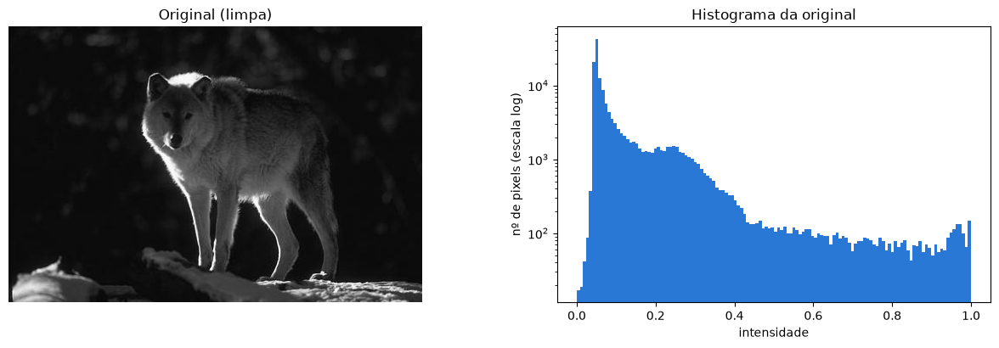

In [14]:
"""PREPARAÇÃO: CAMINHOS, BIBLIOTECAS, FUNÇÕES AUXILIARES E CARREGAMENTO DA IMAGEM"""
# %pip install numpy scipy matplotlib pillow scikit-image pandas
import heapq
import os
from collections import deque
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from PIL import Image
from scipy.ndimage import distance_transform_edt
from IPython.display import display
# Versão com implementação própria: Watershed, SLIC e rotulagem de componentes são do grupo (etapa 5).
# O scikit-image só é importado nas células de conferência.

ARQUIVO = '42078.jpg'

# Ajusta a pasta de execução quando o notebook é aberto a partir da raiz do repositório (VS Code)
# ou quando a pasta M2-2 inteira é enviada para /content no Colab.
if not (Path('data') / ARQUIVO).exists() and (Path('M2-2') / 'data' / ARQUIVO).exists():
    os.chdir('M2-2')
CAMINHO = Path('data') / ARQUIVO
if not CAMINHO.exists():
    raise FileNotFoundError(f'Imagem não encontrada em {CAMINHO.resolve()}: envie a pasta M2-2 (com data/) para o ambiente.')


def painel(imagens, titulos, colunas=3, figsize=None, vmin=0, vmax=1, cmap='gray'):
    """Mostra várias imagens lado a lado, todas com a mesma escala de intensidade (vmin, vmax)."""
    linhas = int(np.ceil(len(imagens) / colunas))
    fig, axs = plt.subplots(linhas, colunas, figsize=figsize or (4.6 * colunas, 3.4 * linhas), squeeze=False)
    for ax, im, titulo in zip(axs.flat, imagens, titulos):
        ax.imshow(im, cmap=cmap, vmin=vmin, vmax=vmax, interpolation='nearest')
        ax.set_title(titulo, fontsize=10)
        ax.axis('off')
    for ax in list(axs.flat)[len(imagens):]:
        ax.axis('off')
    fig.tight_layout()
    plt.show()


def conv2d(img, kernel):
    """Convolução 2D manual (a mesma do trabalho M1-1): o kernel é espelhado (rotação de 180°) e, para cada
    posição (a, b) dele, a imagem deslocada é multiplicada pelo peso e acumulada. Bordas por replicação."""
    img = np.asarray(img, dtype=np.float64)
    kernel = np.asarray(kernel, dtype=np.float64)[::-1, ::-1]
    kh, kw = kernel.shape
    padded = np.pad(img, ((kh // 2, kh // 2), (kw // 2, kw // 2)), mode='edge')
    h, w = img.shape
    out = np.zeros((h, w))
    for a in range(kh):
        for b in range(kw):
            out += kernel[a, b] * padded[a:a + h, b:b + w]
    return out


SOBEL_X = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], dtype=np.float64)
SOBEL_Y = SOBEL_X.T.copy()


def gradiente_sobel(img):
    """Magnitude do gradiente de Sobel, sqrt(gx² + gy²), calculada com a conv2d manual."""
    return np.sqrt(conv2d(img, SOBEL_X) ** 2 + conv2d(img, SOBEL_Y) ** 2)


def recortar(img, caixa):
    x, y, largura, altura = caixa
    return img[y:y + altura, x:x + largura]


# Recortes fixos (x, y, largura, altura), escolhidos sobre a imagem limpa e usados em todas as comparações visuais
RECORTES = {
    'lobo (cabeça e dorso)': (150, 45, 180, 110),   # contorno do objeto contra o fundo
    'fundo escuro (floresta)': (0, 5, 140, 105),   # região sem objeto, quase lisa
    'patas e neve': (190, 200, 200, 115),          # estruturas finas e textura clara
}
RECORTE_OBJETO = 'lobo (cabeça e dorso)'   # recorte usado nos painéis de detalhe das etapas 3 a 6

# Carregamento: 8 bits em tons de cinza -> float64 em [0, 1]
limpa = np.asarray(Image.open(CAMINHO).convert('L'), dtype=np.float64) / 255.0
M, N = limpa.shape
print(f'Imagem: {CAMINHO} | {M} linhas x {N} colunas | intensidade em [{limpa.min():.3f}, {limpa.max():.3f}] | '
      f'média {limpa.mean():.3f} | desvio-padrão {limpa.std():.3f}')

fig, axs = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={'width_ratios': [1.4, 1]})
axs[0].imshow(limpa, cmap='gray', vmin=0, vmax=1)
axs[0].set_title('Original (limpa)')
axs[0].axis('off')
axs[1].hist(limpa.ravel(), bins=128, range=(0, 1), color='#2a78d6')
axs[1].set_title('Histograma da original')
axs[1].set_xlabel('intensidade')
axs[1].set_ylabel('nº de pixels (escala log)')
axs[1].set_yscale('log')   # o fundo escuro concentra 2/3 dos pixels em poucas faixas de intensidade
fig.tight_layout()
plt.show()

2. Adicionar ruído gaussiano ou speckle à imagem.

σ nominal = 0.0980 | σ efetivo = 0.0984 | média do ruído = -0.0003 | pixels fora de [0, 1] (mantidos) = 20.79%
Se a ruidosa fosse saturada: 20.79% dos pixels saturariam | σ efetivo = 0.0826 | média do ruído = +0.0120
  Pixels escuros (limpa <= 0,1; 66.2% da imagem): com saturação, média = +0.0178 e σ = 0.0749 | sem saturação, média = -0.0002 e σ = 0.0983


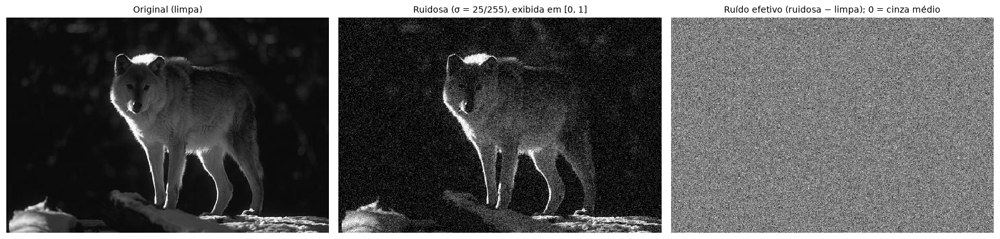

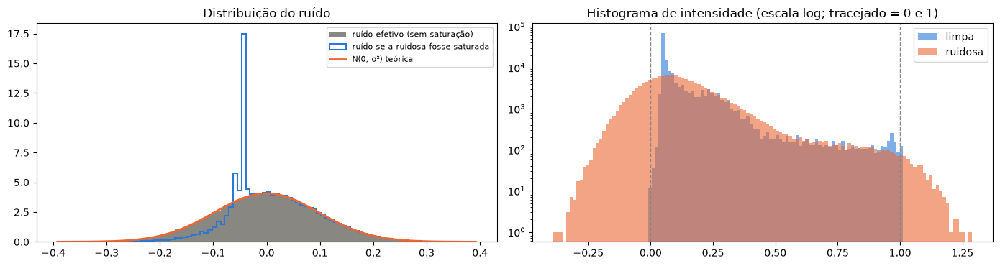

In [15]:
"""ETAPA 2: RUÍDO GAUSSIANO ADITIVO"""
SIGMA_RUIDO = 25 / 255   # desvio-padrão do ruído (σ = 25 na escala 0-255)
SEMENTE = 42             # semente fixa: o mesmo ruído em todas as execuções


def adicionar_ruido_gaussiano(img, sigma, semente, saturar=False):
    """g = f + n, com n ~ N(0, σ²) sorteado de forma independente em cada pixel (ruído branco aditivo).
    Por padrão o resultado fica em ponto flutuante, sem saturação (ver a justificativa). Com saturar=True,
    g = clip(f + n, 0, 1); aqui isso só é usado para mostrar o que a saturação faria nesta imagem escura."""
    rng = np.random.default_rng(semente)
    g = img + rng.normal(0.0, sigma, img.shape)
    return np.clip(g, 0.0, 1.0) if saturar else g


ruidosa = adicionar_ruido_gaussiano(limpa, SIGMA_RUIDO, SEMENTE)
ruido = ruidosa - limpa   # ruído efetivo: sem saturação, é o próprio n sorteado
print(f'σ nominal = {SIGMA_RUIDO:.4f} | σ efetivo = {ruido.std():.4f} | média do ruído = {ruido.mean():+.4f} | '
      f'pixels fora de [0, 1] (mantidos) = {np.mean((ruidosa < 0) | (ruidosa > 1)):.2%}')

# Diagnóstico: o que a saturação em [0, 1] faria com o MESMO ruído (mesma semente) nesta imagem
saturada = adicionar_ruido_gaussiano(limpa, SIGMA_RUIDO, SEMENTE, saturar=True)
ruido_saturado = saturada - limpa
escuros = limpa <= 0.1
print(f'Se a ruidosa fosse saturada: {np.mean((saturada <= 0) | (saturada >= 1)):.2%} dos pixels saturariam | '
      f'σ efetivo = {ruido_saturado.std():.4f} | média do ruído = {ruido_saturado.mean():+.4f}')
print(f'  Pixels escuros (limpa <= 0,1; {escuros.mean():.1%} da imagem): com saturação, média = '
      f'{ruido_saturado[escuros].mean():+.4f} e σ = {ruido_saturado[escuros].std():.4f} | sem saturação, média = '
      f'{ruido[escuros].mean():+.4f} e σ = {ruido[escuros].std():.4f}')

painel([limpa, ruidosa, 0.5 + ruido / (8 * SIGMA_RUIDO)],
       ['Original (limpa)', 'Ruidosa (σ = 25/255), exibida em [0, 1]', 'Ruído efetivo (ruidosa − limpa); 0 = cinza médio'],
       3, figsize=(16, 4.2))

# Histogramas: o ruído segue a gaussiana teórica; a versão saturada mostra a deformação que foi evitada
x = np.linspace(-4 * SIGMA_RUIDO, 4 * SIGMA_RUIDO, 200)
fig, axs = plt.subplots(1, 2, figsize=(14, 3.8))
axs[0].hist(ruido.ravel(), bins=100, range=(x[0], x[-1]), density=True, color='#898781',
            label='ruído efetivo (sem saturação)')
axs[0].hist(ruido_saturado.ravel(), bins=100, range=(x[0], x[-1]), density=True, histtype='step', lw=1.5,
            color='#2a78d6', label='ruído se a ruidosa fosse saturada')
axs[0].plot(x, np.exp(-x ** 2 / (2 * SIGMA_RUIDO ** 2)) / (SIGMA_RUIDO * np.sqrt(2 * np.pi)),
            color='#eb6834', lw=2, label='N(0, σ²) teórica')
axs[0].set_title('Distribuição do ruído')
axs[0].legend(fontsize=8)
faixa = (min(0.0, ruidosa.min()), max(1.0, ruidosa.max()))
axs[1].hist(limpa.ravel(), bins=128, range=faixa, alpha=0.6, color='#2a78d6', label='limpa')
axs[1].hist(ruidosa.ravel(), bins=128, range=faixa, alpha=0.6, color='#eb6834', label='ruidosa')
for limite in (0, 1):
    axs[1].axvline(limite, color='#898781', ls='--', lw=1)
axs[1].set_yscale('log')
axs[1].set_title('Histograma de intensidade (escala log; tracejado = 0 e 1)')
axs[1].legend()
fig.tight_layout()
plt.show()


**Justificativa**

- **Tipo de ruído: gaussiano aditivo.**
  - O modelo é $g = f + n$, com $n \sim \mathcal{N}(0, \sigma^2)$ sorteado de forma independente em cada pixel. Esse ruído é *branco*: tem a mesma potência em todas as frequências.
  - A energia de uma imagem natural, por outro lado, se concentra nas baixas frequências. Logo, existe uma faixa de alta frequência em que o ruído domina, e um passa-baixa linear no domínio da frequência (etapa 3) é o tratamento adequado para esse modelo.
  - O speckle é multiplicativo ($g = f + f \cdot n$) e depende da intensidade do pixel. O tratamento correto para ele seria uma filtragem homomórfica (log → filtro → exp), que fugiria do que a etapa 3 pede.
- **Intensidade: σ = 25/255 ≈ 0,098.** É um dos níveis padrão em trabalhos de remoção de ruído (σ ∈ {15, 25, 50} na escala 0–255). A imagem fica visivelmente degradada (PSNR = 20,14 dB, etapa 4), mas o lobo continua reconhecível, o que deixa espaço para medir a melhora da filtragem.
- **Semente fixa (42):** gera o mesmo ruído em todas as execuções, para que os números deste notebook sejam reproduzíveis.
- **Sem saturação em [0, 1].**
  - Esta imagem é muito escura: 66,2% dos pixels têm intensidade ≤ 0,1, ou seja, estão a cerca de 1 σ do zero. Se a ruidosa fosse saturada em [0, 1] (`clip`), **20,8% dos pixels** iriam para os limites, quase todos para 0 (diagnóstico impresso acima).
  - Nos pixels escuros, o ruído deixaria de ser gaussiano de média zero: a parte negativa seria cortada, e o ruído passaria a ter **média +0,018 e σ = 0,075**, contra −0,0002 e 0,098 sem saturação. O fundo ficaria em média mais claro (viés positivo) e com menos variância, e o ruído passaria a depender da intensidade do pixel. Isso quebra o modelo de ruído branco usado na etapa 3 para escolher o corte, e um passa-baixa não remove um viés: ele passaria direto para a imagem filtrada. Na imagem toda, o σ efetivo cairia de 0,098 para 0,083.
  - Por isso, como é comum nos testes de remoção de ruído com σ ∈ {15, 25, 50}, a ruidosa é mantida em ponto flutuante, sem saturação: os 20,8% de pixels fora de [0, 1] ficam como estão. O ruído efetivo (ruidosa − limpa) é exatamente o $n$ sorteado (σ efetivo = 0,0984, média −0,0003). O efeito da saturação sobre o ruído é estudado em Foi (2009), *Clipped noisy images: heteroskedastic modeling and practical denoising*.
  - A saturação só acontece na exibição (escala de cinza de 0 a 1) e na saída do filtro (etapa 3): a imagem filtrada é uma estimativa da imagem limpa e por isso deve ficar em [0, 1].
- **Histogramas:**
  - O ruído efetivo segue a gaussiana teórica. A versão saturada (contorno azul) mostra a deformação evitada: um pico estreito em torno de −0,04 (e outro menor perto de −0,06), formado pelos pixels do fundo, com intensidade de 0,04 a 0,06, cortados em 0, e uma cauda esquerda mais curta que a da gaussiana.
  - Na imagem, a limpa tem um pico estreito em torno de 0,05 (o fundo), uma segunda elevação entre 0,2 e 0,3 (a pelagem) e um pequeno acúmulo perto de 1 (a linha de luz e a neve). O ruído espalha o pico do fundo para os dois lados, e a ruidosa vai de cerca de −0,4 a 1,3.

3. Realizar filtragem no domínio da frequência (ex.: com filtro Gaussiano ou Butterworth na
frequência). A escolha do filtro será avaliada.
    - Mostrar espectros antes e depois.
    - Aplicar a transformada inversa para retornar ao domínio espacial.

Patamar do ruído estimado = 0.01013 (σ² real do ruído = 0.00969)
f_c a priori (SNR = 1) = 0.17 ciclos/pixel | período 1/f_c = 5.9 px | σ espacial do gaussiano 1/(2π f_c) = 0.94 px


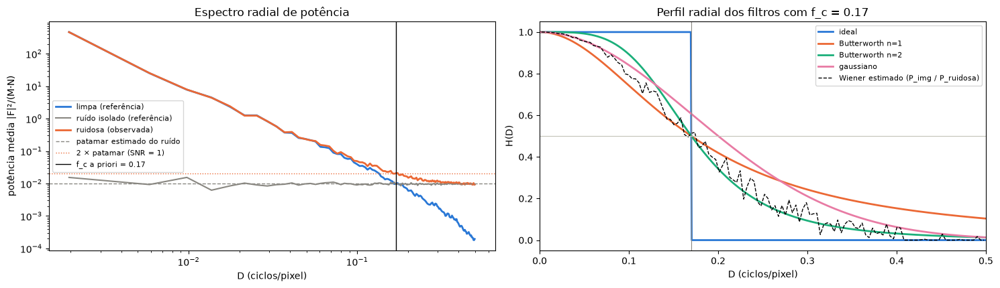

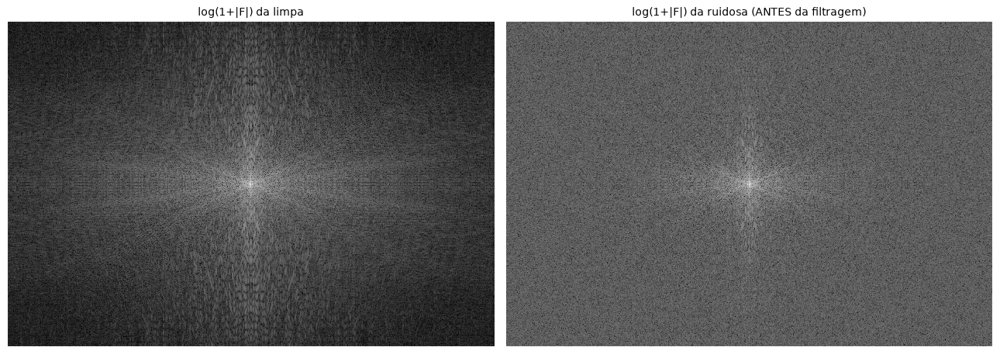

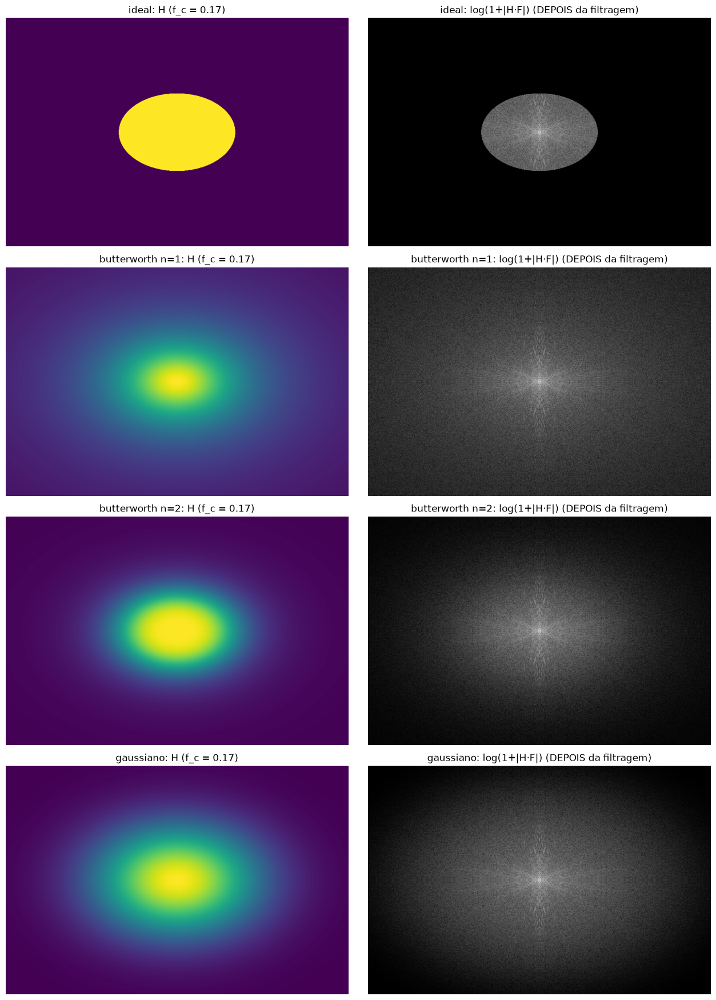

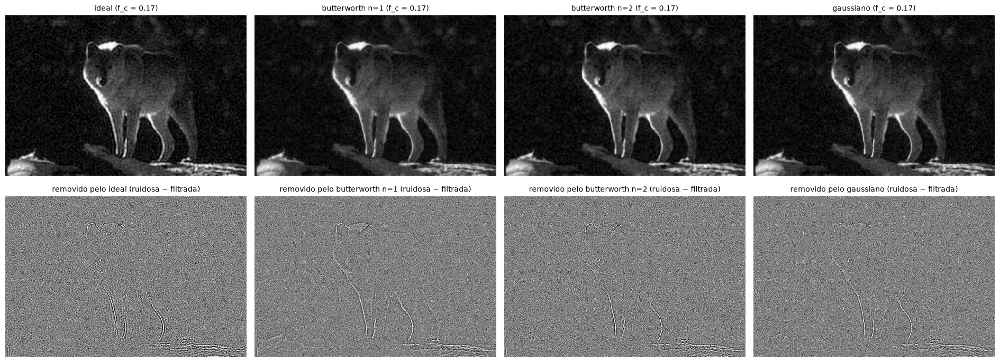

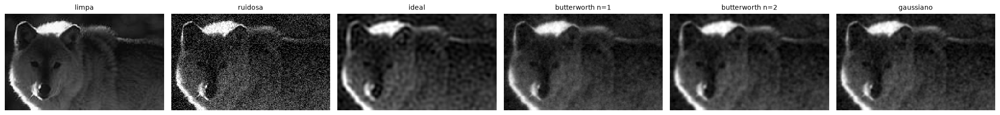

In [16]:
"""ETAPA 3: FILTRAGEM PASSA-BAIXA NO DOMÍNIO DA FREQUÊNCIA"""


def preencher(img):
    """Preenchimento por reflexão de meia imagem em cada lado (M2-1). A DFT supõe que a imagem é periódica,
    e a reflexão evita a descontinuidade artificial entre bordas opostas."""
    M, N = img.shape
    return np.pad(img, ((M // 2, M // 2), (N // 2, N // 2)), mode='reflect')


def distancia_frequencia(shape):
    """D(u, v) em ciclos/pixel, com a frequência zero no centro (após fftshift). Cada eixo é normalizado
    pela própria dimensão, então o corte é o mesmo nas linhas e nas colunas de uma imagem retangular."""
    M, N = shape
    fy = np.fft.fftshift(np.fft.fftfreq(M))[:, None]
    fx = np.fft.fftshift(np.fft.fftfreq(N))[None, :]
    return np.sqrt(fy ** 2 + fx ** 2)


def criar_passa_baixa(shape, fc, tipo, n=2):
    """H(D) do passa-baixa com corte fc (ciclos/pixel): ideal, Butterworth de ordem n ou gaussiano."""
    D = distancia_frequencia(shape)
    if tipo == 'ideal':
        return (D <= fc).astype(np.float64)
    if tipo == 'butterworth':
        return 1.0 / (1.0 + (D / fc) ** (2 * n))
    if tipo == 'gaussiano':
        return np.exp(-D ** 2 / (2 * fc ** 2))
    raise ValueError(f'Filtro desconhecido: {tipo}')


def espectro(img):
    """F(u, v) centralizado (fftshift) da imagem preenchida."""
    return np.fft.fftshift(np.fft.fft2(preencher(img)))


def filtrar_frequencia(img, fc, tipo, n=2, F=None):
    """g = Re{F⁻¹[H·F]}, recortado de volta para o tamanho original. Retorna (g, F, H).
    F pode ser passado pronto para não recalcular a FFT da mesma imagem a cada filtro testado."""
    M, N = img.shape
    if F is None:
        F = espectro(img)
    H = criar_passa_baixa(F.shape, fc, tipo, n)
    g = np.real(np.fft.ifft2(np.fft.ifftshift(H * F)))   # ifftshift antes da inversa
    g = g[M // 2:M // 2 + M, N // 2:N // 2 + N]           # remove o preenchimento
    return np.clip(g, 0.0, 1.0), F, H                     # estimativa da limpa: fica em [0, 1]


def espectro_radial(img, largura_anel=1 / 256):
    """Média azimutal da potência |F|²/(M·N) em anéis de largura fixa em D. Com essa normalização, um ruído
    branco de variância σ² tem potência média ≈ σ² em todas as frequências (teorema de Parseval)."""
    F = espectro(img)
    P = np.abs(F) ** 2 / F.size
    anel = (distancia_frequencia(F.shape) / largura_anel).astype(int).ravel()
    soma = np.bincount(anel, weights=P.ravel())
    conta = np.bincount(anel)
    d = (np.arange(len(soma)) + 0.5) * largura_anel
    validos = (conta > 0) & (d <= 0.5)
    return d[validos], soma[validos] / conta[validos]


# --- 3.1 Escolha do corte a priori pelo espectro radial (usa apenas a imagem ruidosa) ---
d, P_ruidosa = espectro_radial(ruidosa)
_, P_limpa = espectro_radial(limpa)    # curvas "verdadeiras", só para conferir a estimativa
_, P_ruido = espectro_radial(ruido)

piso = P_ruidosa[d >= 0.35].mean()     # patamar do ruído: nas altas frequências quase só há ruído
# Onde a imagem tem a mesma potência do ruído, P_ruidosa ≈ P_imagem + piso = 2·piso (SNR = 1 por frequência)
cruzamento = np.nonzero((d > 0.01) & (P_ruidosa <= 2 * piso))[0][0]
FC_A_PRIORI = round(float(d[cruzamento]), 2)
# Ganho de Wiener estimado: fração da potência em cada frequência que é imagem, e não ruído
wiener = np.clip(P_ruidosa - piso, 0, None) / P_ruidosa

print(f'Patamar do ruído estimado = {piso:.5f} (σ² real do ruído = {ruido.var():.5f})')
print(f'f_c a priori (SNR = 1) = {FC_A_PRIORI:.2f} ciclos/pixel '
      f'| período 1/f_c = {1 / FC_A_PRIORI:.1f} px | σ espacial do gaussiano 1/(2π f_c) = {1 / (2 * np.pi * FC_A_PRIORI):.2f} px')

fig, axs = plt.subplots(1, 2, figsize=(15, 4.4))
axs[0].loglog(d, P_limpa, color='#2a78d6', lw=2, label='limpa (referência)')
axs[0].loglog(d, P_ruido, color='#898781', lw=1.5, label='ruído isolado (referência)')
axs[0].loglog(d, P_ruidosa, color='#eb6834', lw=2, label='ruidosa (observada)')
axs[0].axhline(piso, color='#898781', ls='--', lw=1, label='patamar estimado do ruído')
axs[0].axhline(2 * piso, color='#eb6834', ls=':', lw=1, label='2 × patamar (SNR = 1)')
axs[0].axvline(FC_A_PRIORI, color='k', lw=1, label=f'f_c a priori = {FC_A_PRIORI:.2f}')
axs[0].set_xlabel('D (ciclos/pixel)')
axs[0].set_ylabel('potência média |F|²/(M·N)')
axs[0].set_title('Espectro radial de potência')
axs[0].legend(fontsize=8)

# Perfis radiais dos filtros candidatos no mesmo corte, comparados ao ganho de Wiener estimado
D_perfil = np.linspace(0, 0.5, 500)
for tipo, n, cor, rotulo in [('ideal', 2, '#2a78d6', 'ideal'), ('butterworth', 1, '#eb6834', 'Butterworth n=1'),
                             ('butterworth', 2, '#1baf7a', 'Butterworth n=2'), ('gaussiano', 2, '#e87ba4', 'gaussiano')]:
    if tipo == 'ideal':
        H_perfil = (D_perfil <= FC_A_PRIORI).astype(float)
    elif tipo == 'butterworth':
        H_perfil = 1 / (1 + (D_perfil / FC_A_PRIORI) ** (2 * n))
    else:
        H_perfil = np.exp(-D_perfil ** 2 / (2 * FC_A_PRIORI ** 2))
    axs[1].plot(D_perfil, H_perfil, color=cor, lw=2, label=rotulo)
axs[1].plot(d, wiener, color='k', lw=1, ls='--', label='Wiener estimado (P_img / P_ruidosa)')
axs[1].axvline(FC_A_PRIORI, color='#898781', lw=0.8)
axs[1].axhline(0.5, color='#c3c2b7', lw=0.8)
axs[1].set_xlim(0, 0.5)
axs[1].set_xlabel('D (ciclos/pixel)')
axs[1].set_ylabel('H(D)')
axs[1].set_title(f'Perfil radial dos filtros com f_c = {FC_A_PRIORI:.2f}')
axs[1].legend(fontsize=8)
fig.tight_layout()
plt.show()

# --- 3.2 Filtragem com o corte a priori: espectros antes e depois ---
CANDIDATOS = {
    'ideal': dict(tipo='ideal'),
    'butterworth n=1': dict(tipo='butterworth', n=1),
    'butterworth n=2': dict(tipo='butterworth', n=2),
    'gaussiano': dict(tipo='gaussiano'),
}
F_ruidosa = espectro(ruidosa)
F_limpa = espectro(limpa)
escala = np.log1p(np.abs(F_ruidosa)).max()   # mesma escala de cor em todos os espectros

painel([np.log1p(np.abs(F_limpa)) / escala, np.log1p(np.abs(F_ruidosa)) / escala],
       ['log(1+|F|) da limpa', 'log(1+|F|) da ruidosa (ANTES da filtragem)'], 2, figsize=(13, 4.6))

filtradas_a_priori = {}
fig, axs = plt.subplots(len(CANDIDATOS), 2, figsize=(13, 4.4 * len(CANDIDATOS)))
for linha, (nome, p) in zip(axs, CANDIDATOS.items()):
    g, _, H = filtrar_frequencia(ruidosa, FC_A_PRIORI, F=F_ruidosa, **p)
    filtradas_a_priori[nome] = g
    linha[0].imshow(H, cmap='viridis', vmin=0, vmax=1)
    linha[0].set_title(f'{nome}: H (f_c = {FC_A_PRIORI:.2f})')
    linha[1].imshow(np.log1p(np.abs(H * F_ruidosa)), cmap='gray', vmin=0, vmax=escala)
    linha[1].set_title(f'{nome}: log(1+|H·F|) (DEPOIS da filtragem)')
for ax in axs.flat:
    ax.axis('off')
fig.tight_layout()
plt.show()

# --- 3.3 Transformada inversa: imagens filtradas e o que cada filtro removeu ---
nomes = list(CANDIDATOS)
painel([filtradas_a_priori[k] for k in nomes] + [0.5 + (ruidosa - filtradas_a_priori[k]) / (8 * SIGMA_RUIDO) for k in nomes],
       [f'{k} (f_c = {FC_A_PRIORI:.2f})' for k in nomes] + [f'removido pelo {k} (ruidosa − filtrada)' for k in nomes],
       4, figsize=(19, 7.2))

caixa = RECORTES[RECORTE_OBJETO]
painel([recortar(im, caixa) for im in [limpa, ruidosa] + [filtradas_a_priori[k] for k in nomes]],
       ['limpa', 'ruidosa'] + nomes, 6, figsize=(21, 3.2))

**Etapas de `filtrar_frequencia`** (adaptada do trabalho M2-1)

1. **Preenchimento por reflexão** de meia imagem em cada lado (321×481 → 641×961). A DFT trata a imagem como periódica; sem o preenchimento, a borda de cima "encostaria" na de baixo e criaria uma descontinuidade artificial, com bordas falsas no resultado.
2. **`fft2` + `fftshift`**, que coloca a frequência zero no centro da matriz.
3. **`criar_passa_baixa`** calcula a distância $D$ ao centro em **ciclos/pixel**, normalizando cada eixo pela própria dimensão. Como a matriz não é quadrada (641×961), o filtro aparece como uma **elipse** na matriz da FFT, mas corresponde a um **círculo** em ciclos/pixel, ou seja, ao mesmo corte em todas as direções. As funções de transferência são:

$$H_I(D)=\begin{cases}1 & D\le f_c\\0 & D>f_c\end{cases},\qquad H_B(D)=\frac{1}{1+(D/f_c)^{2n}},\qquad H_G(D)=e^{-D^2/(2f_c^2)}$$

4. **Produto ponto a ponto** $H\cdot F$, `ifftshift`, `ifft2` e parte real: $g=\Re\{\mathcal{F}^{-1}[H\cdot F]\}$.
5. **Recorte** de volta para 321×481 e saturação em [0, 1], porque o ringing pode gerar valores fora da faixa.

**Escolha do corte a priori: espectro radial (usa só a imagem ruidosa)**

- O espectro radial (média da potência em anéis de mesma frequência) confirma o modelo da etapa 2:
  - a potência da imagem cai com a frequência, quase como uma reta no gráfico log-log, comportamento típico de imagens naturais;
  - o ruído é um patamar plano.
- **Patamar do ruído:** estimado nas altas frequências da ruidosa ($D \ge 0{,}35$), dá 0,0101, próximo do σ² real de 0,0097. A pequena diferença é a pouca potência que a imagem ainda tem nessa faixa.
- **Corte:** onde a curva da ruidosa cai para 2 × patamar, imagem e ruído têm a mesma potência (SNR = 1 por frequência). Isso acontece em **$f_c$ = 0,17 ciclos/pixel**, período de cerca de 5,9 px (no gaussiano, σ espacial de 0,94 px). Acima desse corte, a maior parte da energia é ruído; abaixo, é imagem.
- **Comparação com Wiener:** o ganho de Wiener estimado, $P_{imagem}/P_{ruidosa}$, é o filtro linear de menor erro quadrático para esse par sinal/ruído e vale 0,5 exatamente no cruzamento.
  - No perfil radial, ele acompanha a curva **gaussiana** até o corte e, acima dele, cai mais rápido, perto do **Butterworth n=2**.
  - O Butterworth n=1 deixa passar uma cauda longa de altas frequências. O ideal corta de forma abrupta uma faixa que ainda tem imagem e mantém todo o ruído abaixo de $f_c$.
- A hipótese, portanto, é: **gaussiano com $f_c$ ≈ 0,17**, com o Butterworth n=2 como alternativa próxima. Ela é testada com PSNR e SSIM na etapa 4.

**Espectros antes e depois**

- **Antes:** comparada à limpa, a ruidosa tem as altas frequências (bordas da matriz) uniformemente claras. É o patamar do ruído branco.
- **Ideal:** zera tudo fora da elipse, inclusive detalhe útil, e mantém todo o ruído de dentro dela.
- **Butterworth n=1:** a transição é lenta e a cauda longa. Uma parte do ruído de alta frequência continua passando, e o fundo do espectro fica cinza.
- **Butterworth n=2 e gaussiano:** a atenuação é gradual, e as altas frequências ficam escuras.

**Imagens filtradas (transformada inversa)**

- **Ideal:** o ringing aparece como halos ao lado das bordas fortes (no recorte, a linha de luz do rosto e o topo da cabeça ganham faixas paralelas), e o fundo escuro fica "manchado".
- **"Removido" (ruidosa − filtrada):** num filtro bom, deveria ser só ruído.
  - No gaussiano e no Butterworth n=2, é quase só ruído. Apenas as bordas mais fortes (a linha de luz das pernas e das orelhas) deixam um traço fraco.
  - No Butterworth n=1, aparece o contorno inteiro do lobo: orelhas, rosto, peito, pernas e a borda da neve. Abaixo do corte, ele atenua mais que o gaussiano (ver o perfil radial) e por isso também remove estrutura da imagem. Ao mesmo tempo, a cauda longa deixa passar mais ruído: no recorte, o fundo dele é o mais granulado entre os filtros suaves.
  - No ideal, as bordas aparecem duplicadas, em faixas paralelas às pernas e à neve: é o ringing visto pelo outro lado.

4. Avaliar a qualidade da filtragem usando métricas como:
    - PSNR (Peak Signal-to-Noise Ratio)
    - (Opcional) SSIM (Structural Similarity Index)

Conferência (limpa x ruidosa): PSNR nosso = 20.1379 dB | skimage = 20.1379 dB
                               SSIM nosso = 0.1870    | skimage = 0.1870


,PSNR (dB),SSIM
f_c a priori = 0.17,,
ruidosa (sem filtro),20.1379,0.1870
ideal,26.9391,0.6388
butterworth n=1,28.0849,0.6555
butterworth n=2,28.1774,0.7055
gaussiano,28.2532,0.6517


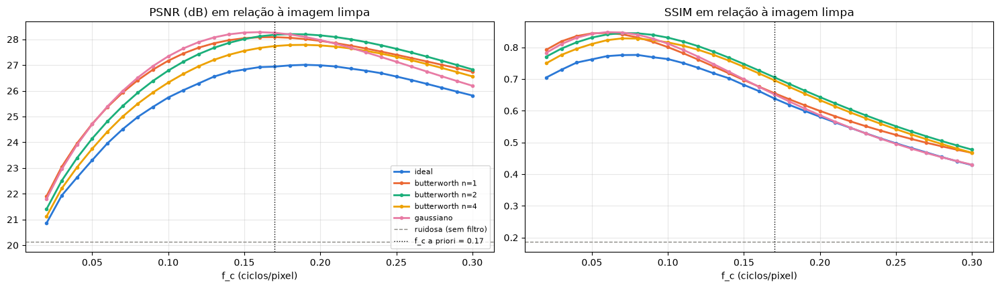

,f_c (máx. PSNR),PSNR (dB),SSIM nesse f_c,f_c (máx. SSIM),SSIM máx.
ideal,0.19,27.0088,0.5995,0.08,0.7761
butterworth n=1,0.17,28.0849,0.6555,0.06,0.8456
butterworth n=2,0.18,28.2019,0.6844,0.07,0.8451
butterworth n=4,0.19,27.7848,0.6538,0.07,0.8283
gaussiano,0.16,28.2787,0.6752,0.06,0.8480
ruidosa (sem filtro),NaN,20.1379,0.1870,NaN,0.1870


Configuração escolhida (máx. PSNR): gaussiano, f_c = 0.16 -> PSNR = 28.28 dB (ruidosa: 20.14 dB) | SSIM = 0.6752 (ruidosa: 0.1870)
Máximo de SSIM da varredura: gaussiano, f_c = 0.06 (SSIM = 0.8480)


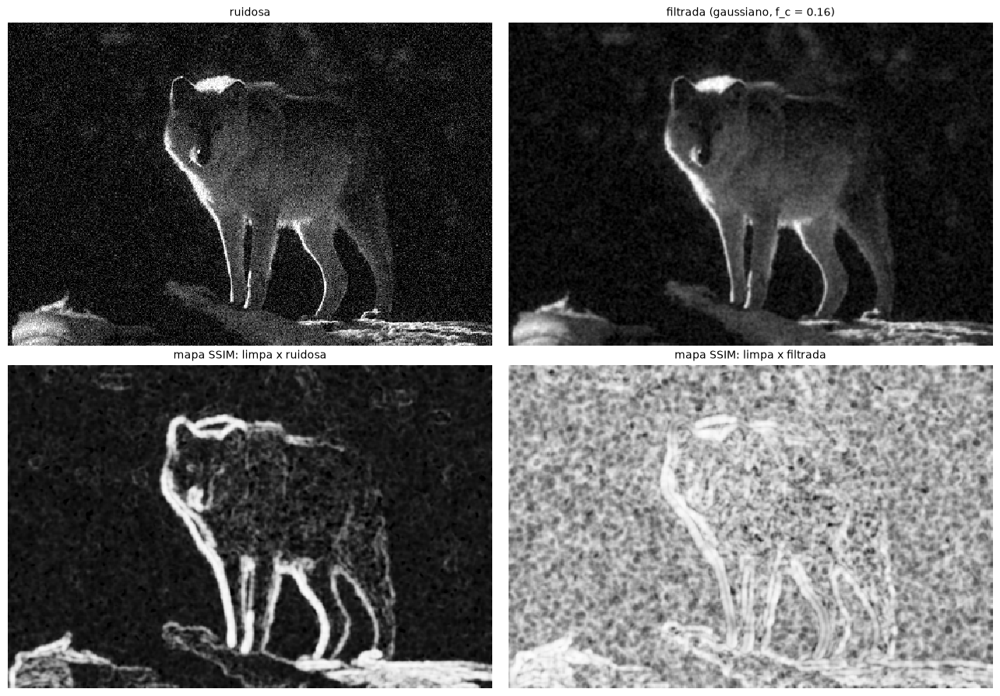

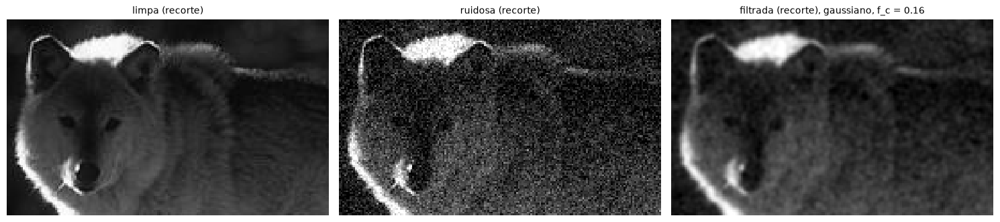

In [17]:
"""ETAPA 4: AVALIAÇÃO DA FILTRAGEM COM PSNR E SSIM (implementação própria)"""


def psnr(ref, img, data_range=1.0):
    """PSNR = 10·log10(MAX² / MSE), em dB. MAX = 1 porque as imagens estão em [0, 1]."""
    mse = np.mean((np.asarray(ref, dtype=np.float64) - np.asarray(img, dtype=np.float64)) ** 2)
    return np.inf if mse == 0 else 10 * np.log10(data_range ** 2 / mse)


def kernel_gaussiano_1d(tamanho=11, sigma=1.5):
    x = np.arange(tamanho) - (tamanho - 1) / 2
    k = np.exp(-x ** 2 / (2 * sigma ** 2))
    return k / k.sum()


# Janela gaussiana 11x11 (σ = 1,5) de Wang et al. (2004). Ela é separável: aplicar 1x11 e depois 11x1
# dá o mesmo resultado da janela 2D, com 22 em vez de 121 deslocamentos na conv2d.
G1 = kernel_gaussiano_1d()[None, :]
RAIO_SSIM = G1.shape[1] // 2


def media_local(img):
    return conv2d(conv2d(img, G1), G1.T)


def ssim(ref, img, data_range=1.0, K1=0.01, K2=0.03):
    """SSIM(x, y) = [(2·μx·μy + C1)(2·σxy + C2)] / [(μx² + μy² + C1)(σx² + σy² + C2)], com médias, variâncias e
    covariância locais ponderadas pela janela gaussiana. Retorna (SSIM médio, mapa). A média ignora a faixa
    de 5 px da borda, onde a janela não cabe inteira (mesma convenção da implementação de referência)."""
    x = np.asarray(ref, dtype=np.float64)
    y = np.asarray(img, dtype=np.float64)
    C1, C2 = (K1 * data_range) ** 2, (K2 * data_range) ** 2
    mx, my = media_local(x), media_local(y)
    sxx = media_local(x * x) - mx ** 2
    syy = media_local(y * y) - my ** 2
    sxy = media_local(x * y) - mx * my
    mapa = ((2 * mx * my + C1) * (2 * sxy + C2)) / ((mx ** 2 + my ** 2 + C1) * (sxx + syy + C2))
    r = RAIO_SSIM
    return mapa[r:-r, r:-r].mean(), mapa


# Conferência das implementações com o scikit-image (usado SOMENTE aqui, para validar)
from skimage.metrics import peak_signal_noise_ratio, structural_similarity
ref_psnr = peak_signal_noise_ratio(limpa, ruidosa, data_range=1)
ref_ssim = structural_similarity(limpa, ruidosa, data_range=1, gaussian_weights=True, sigma=1.5,
                                 use_sample_covariance=False)
print(f'Conferência (limpa x ruidosa): PSNR nosso = {psnr(limpa, ruidosa):.4f} dB | skimage = {ref_psnr:.4f} dB')
print(f'                               SSIM nosso = {ssim(limpa, ruidosa)[0]:.4f}    | skimage = {ref_ssim:.4f}')

# --- 4.1 Métricas das versões filtradas com o corte a priori (etapa 3) ---
a_priori = {'ruidosa (sem filtro)': ruidosa, **filtradas_a_priori}
display(pd.DataFrame({nome: {'PSNR (dB)': psnr(limpa, im), 'SSIM': ssim(limpa, im)[0]}
                      for nome, im in a_priori.items()}).T.round(4)
        .rename_axis(f'f_c a priori = {FC_A_PRIORI:.2f}'))

# --- 4.2 Varredura do corte para cada família de filtro ---
FAMILIAS = {
    'ideal': dict(tipo='ideal'),
    'butterworth n=1': dict(tipo='butterworth', n=1),
    'butterworth n=2': dict(tipo='butterworth', n=2),
    'butterworth n=4': dict(tipo='butterworth', n=4),
    'gaussiano': dict(tipo='gaussiano'),
}
CORTES = np.round(np.arange(0.02, 0.301, 0.01), 2)   # ciclos/pixel

linhas = []
for familia, p in FAMILIAS.items():
    for fc in CORTES:
        g = filtrar_frequencia(ruidosa, fc, F=F_ruidosa, **p)[0]
        linhas.append({'filtro': familia, 'f_c': fc, 'PSNR (dB)': psnr(limpa, g), 'SSIM': ssim(limpa, g)[0]})
varredura = pd.DataFrame(linhas)

base_psnr, base_ssim = psnr(limpa, ruidosa), ssim(limpa, ruidosa)[0]
cores = {'ideal': '#2a78d6', 'butterworth n=1': '#eb6834', 'butterworth n=2': '#1baf7a',
         'butterworth n=4': '#eda100', 'gaussiano': '#e87ba4'}
fig, axs = plt.subplots(1, 2, figsize=(15, 4.4))
for ax, metrica, base in zip(axs, ['PSNR (dB)', 'SSIM'], [base_psnr, base_ssim]):
    for familia, dados in varredura.groupby('filtro', sort=False):
        ax.plot(dados['f_c'], dados[metrica], '-o', ms=3, lw=2, color=cores[familia], label=familia)
    ax.axhline(base, color='#898781', ls='--', lw=1, label='ruidosa (sem filtro)')
    ax.axvline(FC_A_PRIORI, color='k', ls=':', lw=1, label=f'f_c a priori = {FC_A_PRIORI:.2f}')
    ax.set_xlabel('f_c (ciclos/pixel)')
    ax.set_title(f'{metrica} em relação à imagem limpa')
    ax.grid(alpha=0.3)
axs[0].legend(fontsize=8)
fig.tight_layout()
plt.show()

# --- 4.3 Melhor corte de cada família e escolha final (maior PSNR) ---
resumo = {}
for familia, dados in varredura.groupby('filtro', sort=False):
    melhor_psnr = dados.loc[dados['PSNR (dB)'].idxmax()]
    melhor_ssim = dados.loc[dados['SSIM'].idxmax()]
    resumo[familia] = {'f_c (máx. PSNR)': melhor_psnr['f_c'], 'PSNR (dB)': melhor_psnr['PSNR (dB)'],
                       'SSIM nesse f_c': melhor_psnr['SSIM'], 'f_c (máx. SSIM)': melhor_ssim['f_c'],
                       'SSIM máx.': melhor_ssim['SSIM']}
resumo = pd.DataFrame(resumo).T
resumo.loc['ruidosa (sem filtro)'] = [np.nan, base_psnr, base_ssim, np.nan, base_ssim]
display(resumo.round(4))

escolha = varredura.loc[varredura['PSNR (dB)'].idxmax()]
FILTRO_ESCOLHIDO = escolha['filtro']
FC_ESCOLHIDO = float(escolha['f_c'])
filtrada = filtrar_frequencia(ruidosa, FC_ESCOLHIDO, F=F_ruidosa, **FAMILIAS[FILTRO_ESCOLHIDO])[0]
melhor_ssim_global = varredura.loc[varredura['SSIM'].idxmax()]
print(f'Configuração escolhida (máx. PSNR): {FILTRO_ESCOLHIDO}, f_c = {FC_ESCOLHIDO:.2f} '
      f'-> PSNR = {psnr(limpa, filtrada):.2f} dB (ruidosa: {base_psnr:.2f} dB) | '
      f'SSIM = {ssim(limpa, filtrada)[0]:.4f} (ruidosa: {base_ssim:.4f})')
print(f'Máximo de SSIM da varredura: {melhor_ssim_global["filtro"]}, f_c = {melhor_ssim_global["f_c"]:.2f} '
      f'(SSIM = {melhor_ssim_global["SSIM"]:.4f})')

# Mapas de SSIM: onde a estrutura local foi perdida (escuro) antes e depois da filtragem
rotulo = f'{FILTRO_ESCOLHIDO}, f_c = {FC_ESCOLHIDO:.2f}'
painel([ruidosa, filtrada, ssim(limpa, ruidosa)[1], ssim(limpa, filtrada)[1]],
       ['ruidosa', f'filtrada ({rotulo})', 'mapa SSIM: limpa x ruidosa', 'mapa SSIM: limpa x filtrada'],
       2, figsize=(13, 9))
caixa = RECORTES[RECORTE_OBJETO]
painel([recortar(im, caixa) for im in (limpa, ruidosa, filtrada)],
       ['limpa (recorte)', 'ruidosa (recorte)', f'filtrada (recorte), {rotulo}'], 3, figsize=(15, 3.6))

**Justificativa das métricas**

- **PSNR**, $10\log_{10}(1/\text{MSE})$ em dB: mede o erro médio pixel a pixel em relação à imagem limpa. É a métrica pedida no enunciado.
- **SSIM** (Wang et al., 2004): compara luminância, contraste e estrutura em janelas locais gaussianas (11×11, σ = 1,5). Fica mais próxima da percepção humana e é sensível à perda de bordas, o que interessa para a segmentação.
- **Implementação:** as duas foram implementadas à mão (o SSIM usa a `conv2d` manual com a janela separável). A conferência com o scikit-image dá os mesmos valores (20,1379 dB e 0,1870); o skimage aparece apenas nessa linha de validação.
- **Referência:** a imagem limpa. Isso só é possível porque o ruído foi adicionado artificialmente.

**Análise**

- **A hipótese da etapa 3 se confirmou.** O máximo de PSNR da varredura inteira (5 famílias × 29 cortes) é o **gaussiano com $f_c$ = 0,16**, um passo abaixo do corte estimado pelo espectro (0,17). No corte a priori, o gaussiano dá 28,25 dB, só 0,03 dB abaixo do máximo.
  - PSNR: de 20,14 para **28,28 dB** (+8,1 dB).
  - SSIM: de 0,187 para **0,675**.
  - O **gaussiano, $f_c$ = 0,16** é a filtragem usada nas etapas 5 e 6.
- **Ranking das famílias (melhor PSNR de cada uma):** gaussiano 28,28 > Butterworth n=2 28,20 > n=1 28,08 > n=4 27,78 > ideal 27,01 dB.
  - Os dois primeiros são os que mais se parecem com o filtro de Wiener estimado (etapa 3): o gaussiano até o corte e o Butterworth n=2 acima dele.
  - Quanto mais abrupta a transição (n=4, ideal), pior o resultado: o corte brusco gera ringing e descarta de uma vez frequências que ainda têm imagem.
- **Cortes ótimos diferentes entre famílias:** gaussiano 0,16, Butterworth n=1 0,17, n=2 0,18, n=4 0,19 e ideal 0,19. Duas coisas explicam a ordem. O ganho em $D = f_c$ não é o mesmo (0,607 no gaussiano, 0,5 no Butterworth), então o gaussiano preserva a mesma faixa com um corte menor. E, entre os Butterworth e o ideal, quanto mais abrupta a transição, maior o corte necessário para não descartar a faixa útil logo acima de $f_c$. Comparar famílias no mesmo $f_c$ não seria justo; por isso cada uma foi avaliada no seu melhor corte.
- **O SSIM discorda do PSNR.** O máximo dele é o gaussiano com $f_c$ = **0,06** (0,848), e todas as famílias têm o pico de SSIM entre 0,06 e 0,08. Nesse corte, o PSNR do gaussiano cai para cerca de 25,4 dB, quase 3 dB abaixo do máximo. Mesmo com $f_c$ = 0,02, um borramento extremo, o SSIM (de 0,70 a 0,79) fica acima do obtido no ótimo de PSNR.
  - O motivo é o fundo escuro, que ocupa dois terços da imagem. Ali a variância local da limpa é quase zero, e o termo de estrutura do SSIM só se recupera quando o ruído residual some, o que pede um borramento forte. Como o SSIM é a média do mapa, essas regiões lisas dominam o valor final.
  - O PSNR mede o erro quadrático, e os erros grandes estão nas bordas do lobo, que um corte baixo borra. Por isso ele prefere um corte maior.
  - O PSNR foi mantido como critério: é a métrica pedida no enunciado, e preservar as bordas importa mais para a segmentação do que limpar o fundo além do necessário.
  - O mesmo efeito explica o SSIM baixo da ruidosa (0,187): no fundo liso, quase toda a variância local é ruído.
- **Formato das curvas:**
  - PSNR: todos os filtros melhoram a ruidosa em todos os cortes testados. Cortes baixos ($f_c$ < 0,10) borram as bordas do lobo, e o PSNR cai rápido. Cortes altos ($f_c$ > 0,20) deixam passar ruído, e a queda é mais lenta. O máximo fica perto do cruzamento SNR = 1.
  - SSIM: cai continuamente a partir do pico em 0,06–0,08; no corte escolhido (0,16), vale 0,675.
- **Mapas de SSIM:**
  - Na ruidosa, só as bordas fortes (a linha de luz do rosto, das orelhas e das pernas, e a borda da neve) mantêm estrutura. O fundo e o interior do lobo ficam pretos.
  - Na filtrada, o fundo clareia bastante, mas fica manchado: o ruído residual abaixo do corte forma "grãos" maiores, que ainda alteram a estrutura local nessa região quase lisa. As bordas continuam claras: o filtro removeu ruído sem apagar os contornos.

**Limitações**

1. **Uso de oráculo.** Escolher pelo máximo de PSNR usa a imagem limpa, informação que não existe na prática. O critério espectral (SNR = 1), que só usa a ruidosa, chegou a 0,17, a 0,03 dB do ótimo, e é ele que seria usado em um caso real.
2. **PSNR não mede segmentação.** PSNR e SSIM medem fidelidade de intensidade e, nesta imagem, nem concordam entre si. A etapa 6 verifica se a melhor filtragem por PSNR também ajuda a segmentar.
3. **Ruído residual.** Um passa-baixa linear não separa ruído e detalhe que ocupam a mesma faixa de frequência: a textura fina da pelagem e da neve é atenuada junto com o ruído, e no fundo sobra um ruído de baixa frequência (as "manchas" do mapa de SSIM).

5. Aplicar segmentação com:
    - Watershed
    - SLIC (Simple Linear Iterative Clustering)

,nº de regiões,área mediana (px),pixels de borda (%)
Watershed clássico,,,
limpa,7099.0,13.0,36.8
ruidosa,16975.0,8.0,61.1
filtrada,13470.0,10.0,54.2


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.29523239318176253..1.2548669686343543].


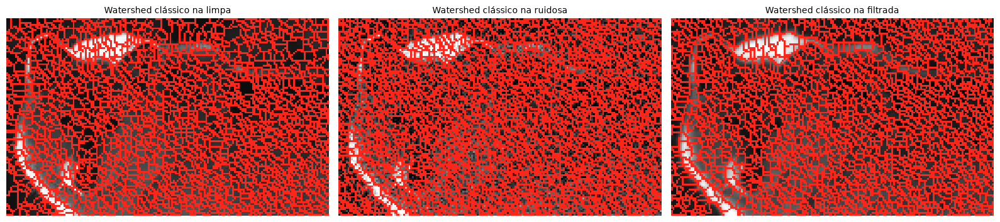

Imagem média por região (cada região pintada com a sua intensidade média), para cada h:


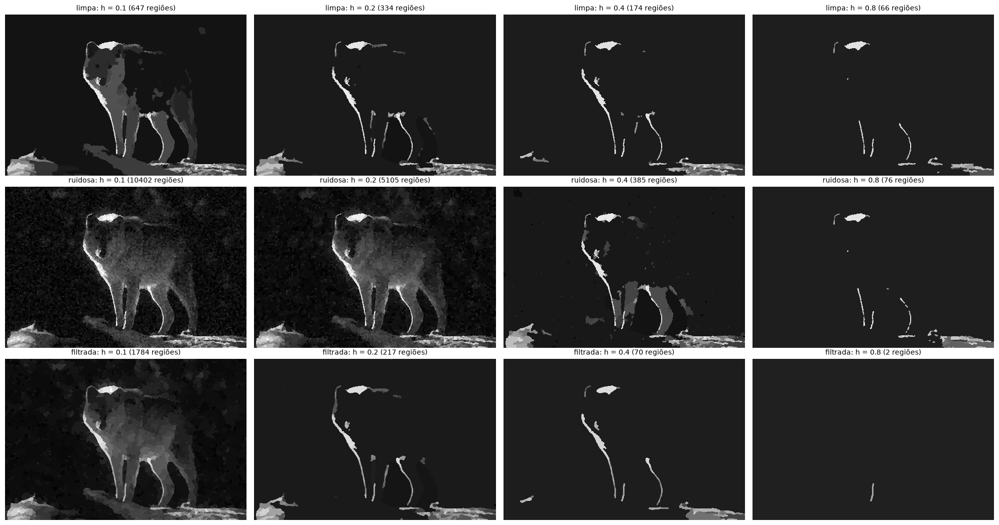

,h = 0.1,h = 0.2,h = 0.4,h = 0.8
Watershed: nº de regiões,,,,
limpa,647,334,174,66
ruidosa,10402,5105,385,76
filtrada,1784,217,70,2


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.29523239318176253..1.2548669686343543].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.2954220686508375..1.2548669686343543].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.29523239318176253..1.2548669686343543].
Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.2954220686508375..1.2548669686343543].


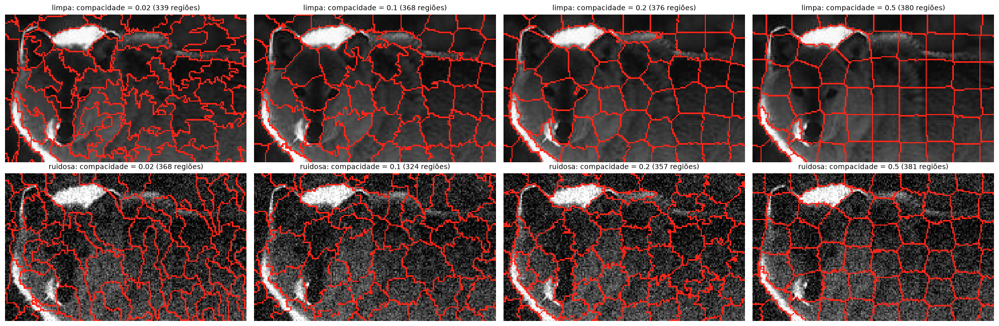

,superpixels (rótulos),pedaços conexos antes da conectividade,regiões depois da conectividade
"SLIC, compacidade 0.1",,,
limpa,384,1445,368
ruidosa,384,39888,324
filtrada,384,1078,370


Parâmetros fixos: Watershed h = 0.2 | SLIC n_segmentos = 400, compacidade = 0.1, 10 iterações


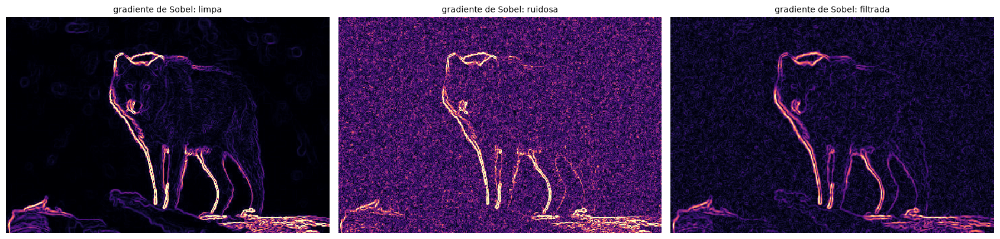

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.3506871851223524..1.2548669686343543].


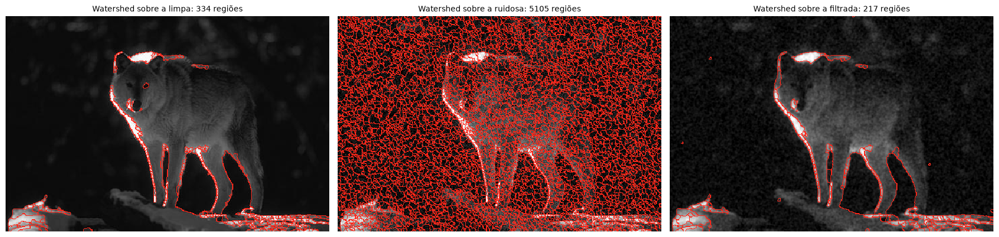

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-0.36756025341812126..1.2877401254438319].


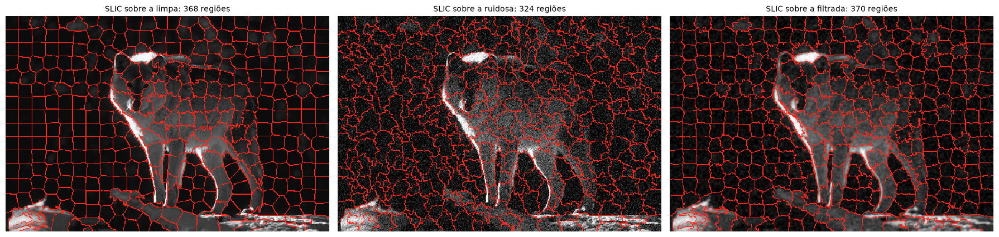

In [18]:
"""ETAPA 5: SEGMENTAÇÃO COM WATERSHED E SLIC (implementação própria)"""
ENTRADAS = {'limpa': limpa, 'ruidosa': ruidosa, 'filtrada': filtrada}

VIZINHOS_4 = [(-1, 0), (0, -1), (0, 1), (1, 0)]
VIZINHOS_8 = VIZINHOS_4 + [(-1, -1), (-1, 1), (1, -1), (1, 1)]


def componentes_conexas(img, fundo=None, vizinhanca=8):
    """Rotulagem de componentes conexas por busca em largura (BFS). Pixels vizinhos com o MESMO valor recebem o
    mesmo rótulo (1, 2, 3, ...); pixels iguais a `fundo` ficam com rótulo 0. Retorna (rótulos, nº de componentes).
    Serve tanto para máscaras binárias (fundo=False) quanto para separar regiões desconexas de um mapa de rótulos."""
    H, W = img.shape
    valores = img.ravel().tolist()            # listas do Python: acesso por índice bem mais rápido que no numpy
    rotulos = [0] * (H * W)
    deslocamentos = VIZINHOS_8 if vizinhanca == 8 else VIZINHOS_4
    n = 0
    for inicio in range(H * W):
        if rotulos[inicio] or valores[inicio] == fundo:
            continue
        n += 1
        valor = valores[inicio]
        rotulos[inicio] = n
        fila = deque([inicio])
        while fila:
            p = fila.popleft()
            y, x = divmod(p, W)
            for dy, dx in deslocamentos:
                yy, xx = y + dy, x + dx
                if 0 <= yy < H and 0 <= xx < W:
                    q = yy * W + xx
                    if not rotulos[q] and valores[q] == valor:
                        rotulos[q] = n
                        fila.append(q)
    return np.array(rotulos, dtype=np.int32).reshape(H, W), n


def watershed_proprio(relevo, marcadores):
    """Inundação de Meyer com fila de prioridade (heapq).
    1) Todos os pixels dos marcadores entram na fila com a altura do relevo.
    2) Sai sempre o pixel MAIS BAIXO da fila (empate: o que entrou primeiro, por isso a `ordem`); cada vizinho
       (vizinhança 4) ainda sem rótulo herda o rótulo dele e entra na fila com a própria altura.
    Assim a "água" de cada marcador sobe pelo relevo e as bacias se encontram nas cristas (bordas). Não há linha de
    divisão: todo pixel termina em alguma região (mesmo comportamento padrão do scikit-image)."""
    H, W = relevo.shape
    altura = relevo.ravel().tolist()
    rotulos = marcadores.ravel().astype(np.int32).tolist()
    fila, ordem = [], 0
    for p, r in enumerate(rotulos):
        if r:
            fila.append((altura[p], ordem, p))
            ordem += 1
    heapq.heapify(fila)
    while fila:
        _, _, p = heapq.heappop(fila)
        y, x = divmod(p, W)
        for dy, dx in VIZINHOS_4:
            yy, xx = y + dy, x + dx
            if 0 <= yy < H and 0 <= xx < W:
                q = yy * W + xx
                if not rotulos[q]:
                    rotulos[q] = rotulos[p]
                    heapq.heappush(fila, (altura[q], ordem, q))
                    ordem += 1
    return np.array(rotulos, dtype=np.int32).reshape(H, W)


def bordas_rotulos(rot):
    """Pixel de borda = pixel cujo vizinho da direita ou de baixo pertence a outra região (linhas de 1 px)."""
    b = np.zeros(rot.shape, dtype=bool)
    b[:, :-1] |= rot[:, :-1] != rot[:, 1:]
    b[:-1, :] |= rot[:-1, :] != rot[1:, :]
    return b


def sobrepor_contornos(img, rot, cor=(1.0, 0.15, 0.1)):
    """Imagem em cinza convertida para RGB com os contornos das regiões pintados."""
    rgb = np.repeat(img[..., None], 3, axis=2)
    rgb[bordas_rotulos(rot)] = cor
    return rgb


def imagem_media_regioes(img, rot):
    """Representação simplificada: cada região pintada com a intensidade média da imagem dentro dela."""
    soma = np.bincount(rot.ravel(), weights=img.ravel())
    conta = np.bincount(rot.ravel())
    return (soma / np.maximum(conta, 1))[rot]


# ------------------------------------------------------------------------------------------------
# Marcadores: mínimos regionais com profundidade >= h (transformada h-mínima, manual)
# ------------------------------------------------------------------------------------------------
def erosao_3x3(img):
    """Erosão em tons de cinza: mínimo da vizinhança 3x3 de cada pixel (bordas por replicação)."""
    h, w = img.shape
    p = np.pad(img, 1, mode='edge')
    out = img.copy()
    for dy in range(3):
        for dx in range(3):
            np.minimum(out, p[dy:dy + h, dx:dx + w], out=out)
    return out


def reconstrucao_por_erosao(marcador, mascara):
    """Reconstrução morfológica por erosão: erode o marcador repetidamente, sem nunca descer abaixo da máscara
    (max com a máscara), até a imagem parar de mudar."""
    atual = marcador
    while True:
        proximo = np.maximum(erosao_3x3(atual), mascara)
        if np.array_equal(proximo, atual):
            return atual
        atual = proximo


def marcadores_h_minimos(relevo, h):
    """Marcadores = mínimos regionais com profundidade >= h (com h = 0, todos os mínimos regionais).
    1) Reconstruir (relevo + h) sobre o relevo "aterra" toda bacia com menos de h de profundidade.
    2) Os mínimos regionais que sobram são os pixels que não podem ser rebaixados ao reconstruir (aterrado + ε):
       nos demais pixels a reconstrução volta exatamente ao valor do aterrado.
    3) Cada mínimo (componente conexa, vizinhança 8) recebe um rótulo com a rotulagem própria."""
    aterrado = reconstrucao_por_erosao(relevo + h, relevo)
    minimos = reconstrucao_por_erosao(aterrado + 1e-6, aterrado) > aterrado
    rotulos, _ = componentes_conexas(minimos, fundo=False, vizinhanca=8)
    return rotulos


# ------------------------------------------------------------------------------------------------
# 5.1 Watershed clássico: um marcador em cada mínimo regional do gradiente
# ------------------------------------------------------------------------------------------------
def watershed_classico(img):
    relevo = gradiente_sobel(img)
    return watershed_proprio(relevo, marcadores_h_minimos(relevo, 0.0))


classico = {nome: watershed_classico(img) for nome, img in ENTRADAS.items()}
display(pd.DataFrame({nome: {'nº de regiões': len(np.unique(rot)),
                             'área mediana (px)': np.median(np.unique(rot, return_counts=True)[1]),
                             'pixels de borda (%)': 100 * bordas_rotulos(rot).mean()}
                      for nome, rot in classico.items()}).T.rename_axis('Watershed clássico').round(1))
caixa = RECORTES[RECORTE_OBJETO]
painel([recortar(sobrepor_contornos(img, classico[nome]), caixa) for nome, img in ENTRADAS.items()],
       [f'Watershed clássico na {nome}' for nome in ENTRADAS], 3, figsize=(16, 3.8))


# ------------------------------------------------------------------------------------------------
# 5.2 Watershed com marcadores (h-mínima)
# ------------------------------------------------------------------------------------------------
WS_H = 0.2   # profundidade mínima das bacias (unidades do gradiente de Sobel; um degrau de 1,0 gera gradiente 4,0)


def segmentar_watershed(img, h=WS_H):
    """Watershed controlado por marcadores: a inundação do gradiente de Sobel parte só dos mínimos profundos."""
    relevo = gradiente_sobel(img)
    return watershed_proprio(relevo, marcadores_h_minimos(relevo, h))


# Teste de h nas três entradas: a imagem média por região mostra quando partes do lobo (pernas, orelhas) são
# "engolidas" pelo fundo (h grande) e quando o fundo escuro se fragmenta em muitas bacias (h pequeno)
TESTE_H = [0.1, 0.2, 0.4, 0.8]
imagens, titulos, contagens_h = [], [], {}
for nome, img in ENTRADAS.items():
    for h in TESTE_H:
        rot = segmentar_watershed(img, h=h)
        contagens_h.setdefault(nome, {})[f'h = {h}'] = len(np.unique(rot))
        imagens.append(imagem_media_regioes(img, rot))
        titulos.append(f'{nome}: h = {h} ({len(np.unique(rot))} regiões)')
print('Imagem média por região (cada região pintada com a sua intensidade média), para cada h:')
painel(imagens, titulos, len(TESTE_H), figsize=(20, 10.5))
display(pd.DataFrame(contagens_h).T.rename_axis('Watershed: nº de regiões'))


# ------------------------------------------------------------------------------------------------
# 5.3 SLIC próprio (Achanta et al., 2012), em tons de cinza
# ------------------------------------------------------------------------------------------------
SLIC_N = 400              # nº desejado de superpixels -> passo S = sqrt(M·N / 400) ≈ 20 px
SLIC_COMPACIDADE = 0.1    # peso da distância espacial (escolhido no teste abaixo)
SLIC_ITERACOES = 10       # Achanta et al. observam convergência em ~10 iterações


def impor_conectividade(rot, tamanho_minimo):
    """Pós-processamento do SLIC: cada pedaço desconexo de um superpixel vira uma componente (vizinhança 4);
    as componentes menores que `tamanho_minimo` são fundidas, da menor para a maior, à componente vizinha com
    quem dividem a maior fronteira. Ao final os rótulos são renumerados 1..K."""
    comp, n = componentes_conexas(rot, vizinhanca=4)
    tamanho = np.bincount(comp.ravel(), minlength=n + 1).astype(np.int64)
    # Fronteiras entre componentes vizinhas: pares (a, b) de pixels adjacentes com rótulos diferentes
    a = np.concatenate([comp[:, :-1].ravel(), comp[:-1, :].ravel()])
    b = np.concatenate([comp[:, 1:].ravel(), comp[1:, :].ravel()])
    dif = a != b
    pares, contagem = np.unique(np.stack([np.concatenate([a[dif], b[dif]]), np.concatenate([b[dif], a[dif]])]),
                                axis=1, return_counts=True)
    vizinhos = {}
    for c, d, k in zip(pares[0].tolist(), pares[1].tolist(), contagem.tolist()):
        vizinhos.setdefault(c, []).append((d, k))
    pai = list(range(n + 1))                  # union-find: cada componente aponta para o grupo onde foi fundida

    def raiz(c):
        while pai[c] != c:
            pai[c] = pai[pai[c]]
            c = pai[c]
        return c

    for c in sorted(range(1, n + 1), key=lambda c: tamanho[c]):
        r = raiz(c)
        if tamanho[r] >= tamanho_minimo:
            continue
        fronteira = {}
        for d, k in vizinhos.get(c, []):
            rd = raiz(d)
            if rd != r:
                fronteira[rd] = fronteira.get(rd, 0) + k
        if fronteira:
            alvo = max(fronteira, key=fronteira.get)
            pai[r] = alvo
            tamanho[alvo] += tamanho[r]
    final = np.array([raiz(c) for c in range(n + 1)])[comp]
    _, renumerado = np.unique(final, return_inverse=True)
    return renumerado.reshape(rot.shape).astype(np.int32) + 1


def slic_proprio(img, n_segmentos=SLIC_N, compacidade=SLIC_COMPACIDADE, iteracoes=SLIC_ITERACOES, conectividade=True):
    """SLIC em tons de cinza: k-means local em (intensidade, linha, coluna).
    1) Centros iniciais em uma grade de passo S = sqrt(M·N/K); cada centro é movido para o pixel de menor gradiente
       na vizinhança 3x3, para não nascer em cima de uma borda.
    2) Atribuição: cada centro só disputa os pixels da janela 2S x 2S ao seu redor, com a distância
       D² = (I - I_c)² + (m/S)²·[(y - y_c)² + (x - x_c)²]   (m = compacidade).
    3) Atualização: cada centro vira a média (y, x, I) dos pixels atribuídos a ele. Repete 2) e 3).
    4) Imposição de conectividade (fragmentos < metade do tamanho médio de um superpixel são fundidos)."""
    H, W = img.shape
    S = int(round(np.sqrt(H * W / n_segmentos)))
    ys, xs = np.meshgrid(np.arange(S // 2, H, S), np.arange(S // 2, W, S), indexing='ij')
    cy, cx = ys.ravel().astype(np.float64), xs.ravel().astype(np.float64)
    grad = gradiente_sobel(img)
    for k in range(len(cy)):
        y0, x0 = int(cy[k]), int(cx[k])
        y1, x1 = max(y0 - 1, 0), max(x0 - 1, 0)
        janela = grad[y1:y0 + 2, x1:x0 + 2]
        dy, dx = np.unravel_index(np.argmin(janela), janela.shape)
        cy[k], cx[k] = y1 + dy, x1 + dx
    ci = img[cy.astype(int), cx.astype(int)].astype(np.float64)
    peso = (compacidade / S) ** 2
    Y, X = np.mgrid[0:H, 0:W]
    for _ in range(iteracoes):
        distancia = np.full((H, W), np.inf)
        rot = np.zeros((H, W), dtype=np.int64)
        for k in range(len(cy)):
            ya, yb = max(int(cy[k] - S), 0), min(int(cy[k] + S) + 1, H)
            xa, xb = max(int(cx[k] - S), 0), min(int(cx[k] + S) + 1, W)
            d = ((img[ya:yb, xa:xb] - ci[k]) ** 2
                 + peso * ((Y[ya:yb, xa:xb] - cy[k]) ** 2 + (X[ya:yb, xa:xb] - cx[k]) ** 2))
            melhor = d < distancia[ya:yb, xa:xb]
            distancia[ya:yb, xa:xb][melhor] = d[melhor]
            rot[ya:yb, xa:xb][melhor] = k
        conta = np.bincount(rot.ravel(), minlength=len(cy))
        ocupado = conta > 0                    # centro sem nenhum pixel mantém a posição anterior
        cy[ocupado] = (np.bincount(rot.ravel(), weights=Y.ravel(), minlength=len(cy)) / np.maximum(conta, 1))[ocupado]
        cx[ocupado] = (np.bincount(rot.ravel(), weights=X.ravel(), minlength=len(cy)) / np.maximum(conta, 1))[ocupado]
        ci[ocupado] = (np.bincount(rot.ravel(), weights=img.ravel(), minlength=len(cy)) / np.maximum(conta, 1))[ocupado]
    if not conectividade:
        return rot.astype(np.int32) + 1
    return impor_conectividade(rot, tamanho_minimo=0.5 * H * W / len(cy))


def segmentar_slic(img, compacidade=SLIC_COMPACIDADE):
    return slic_proprio(img, compacidade=compacidade)


TESTE_COMPACIDADE = [0.02, 0.1, 0.2, 0.5]
imagens, titulos = [], []
for nome in ('limpa', 'ruidosa'):
    for c in TESTE_COMPACIDADE:
        rot = segmentar_slic(ENTRADAS[nome], compacidade=c)
        imagens.append(recortar(sobrepor_contornos(ENTRADAS[nome], rot), caixa))
        titulos.append(f'{nome}: compacidade = {c} ({len(np.unique(rot))} regiões)')
painel(imagens, titulos, 4, figsize=(20, 6.6))

# Diagnóstico: quantos pedaços desconexos o k-means local deixa ANTES da imposição de conectividade
pedacos = {}
for nome, img in ENTRADAS.items():
    bruto = slic_proprio(img, conectividade=False)
    pedacos[nome] = {'superpixels (rótulos)': len(np.unique(bruto)),
                     'pedaços conexos antes da conectividade': componentes_conexas(bruto, vizinhanca=4)[1],
                     'regiões depois da conectividade': len(np.unique(segmentar_slic(img)))}
display(pd.DataFrame(pedacos).T.rename_axis(f'SLIC, compacidade {SLIC_COMPACIDADE}'))


# ------------------------------------------------------------------------------------------------
# 5.4 Segmentação das três entradas com os mesmos parâmetros
# ------------------------------------------------------------------------------------------------
segmentacoes = {}
for metodo, segmentar in (('Watershed', segmentar_watershed), ('SLIC', segmentar_slic)):
    for nome, img in ENTRADAS.items():
        segmentacoes[(metodo, nome)] = segmentar(img)
print(f'Parâmetros fixos: Watershed h = {WS_H} | SLIC n_segmentos = {SLIC_N}, compacidade = {SLIC_COMPACIDADE}, '
      f'{SLIC_ITERACOES} iterações')

# Relevo usado pelo Watershed: magnitude do gradiente de Sobel (mesma escala nas três entradas)
gradientes = {nome: gradiente_sobel(img) for nome, img in ENTRADAS.items()}
vmax = np.percentile(gradientes['limpa'], 99)
painel(list(gradientes.values()), [f'gradiente de Sobel: {nome}' for nome in gradientes], 3,
       figsize=(17, 4), vmax=vmax, cmap='magma')

# Contornos sobre a própria imagem segmentada
for metodo in ('Watershed', 'SLIC'):
    painel([sobrepor_contornos(img, segmentacoes[(metodo, nome)]) for nome, img in ENTRADAS.items()],
           [f'{metodo} sobre a {nome}: {len(np.unique(segmentacoes[(metodo, nome)]))} regiões' for nome in ENTRADAS],
           3, figsize=(18, 4.4))

**Justificativa e implementação**

- **Mesmas entradas, mesmos parâmetros.** Os dois métodos são aplicados à limpa (referência), à ruidosa (efeito do ruído) e à filtrada (efeito do pré-processamento), sempre com os mesmos parâmetros. Assim, qualquer diferença no resultado vem da entrada.

**Funções implementadas pelo grupo**

- **`componentes_conexas`:** rotulagem por busca em largura (BFS) com fila `deque`. Cada pixel ainda sem rótulo inicia uma componente nova, que se espalha pelos vizinhos com o mesmo valor. É usada para rotular os marcadores do Watershed (vizinhança 8) e para separar os pedaços desconexos do SLIC (vizinhança 4).
- **`watershed_proprio`:** inundação de Meyer com fila de prioridade (`heapq`).
  - Os pixels dos marcadores entram na fila. Sai sempre o pixel mais baixo do relevo, e cada vizinho sem rótulo herda o rótulo dele e entra na fila.
  - A `ordem` de chegada desempata pixels de mesma altura (FIFO), para que a água avance por igual nos platôs.
- **`marcadores_h_minimos`:** mínimos regionais com profundidade ≥ h, obtidos por reconstrução morfológica por erosão (com h = 0, são todos os mínimos regionais).
- **`slic_proprio`:** segue Achanta et al. (2012), em tons de cinza.
  1. Centros em uma grade de passo $S$, cada um movido para o menor gradiente da vizinhança 3×3 para não nascer sobre uma borda.
  2. Atribuição de cada pixel ao centro mais próximo, considerando só os centros cuja janela 2S×2S o contém, com $D^2 = (I-I_c)^2 + (m/S)^2[(y-y_c)^2+(x-x_c)^2]$.
  3. Atualização dos centros pela média, por 10 iterações.
  4. Imposição de conectividade.
- **`impor_conectividade`:** os pedaços desconexos menores que metade do tamanho médio de um superpixel são fundidos, do menor para o maior, ao vizinho com quem dividem a maior fronteira. Os grupos são acompanhados com union-find.

**Watershed**

- **Relevo:** magnitude do gradiente de Sobel (`conv2d` manual). As bordas viram cristas e as regiões homogêneas viram bacias.
  - Na limpa, a linha de luz do contorno (rosto, orelhas, topo da cabeça e pernas) e a neve formam cristas fortes. O lado em sombra (dorso à direita e barriga) forma só uma crista fraca.
  - Na ruidosa, o fundo vira um relevo cheio de cristas e vales de ruído; na filtrada, sobra uma textura fraca.
- **Watershed clássico (5.1): o problema do enunciado.** Inundando a partir de *todos* os mínimos regionais:
  - a limpa já vira 7099 regiões (mediana de 13 px, 36,8% dos pixels de borda);
  - a ruidosa vai a 16 975;
  - a filtrada volta a 13 470.
  - A filtragem reduz essa supersegmentação em 21%, mas o resultado continua inútil para comparar contornos: no recorte, as três entradas ficam cobertas por uma malha de regiões.
- **Watershed com marcadores (5.2), usado no restante do trabalho.** Só os mínimos com profundidade ≥ h viram marcadores: as bacias rasas são "aterradas" antes da inundação. O ruído cria mínimos profundos, que sobrevivem ao h, e a filtragem os torna rasos.
- **Teste de h** (nº de regiões):

| | h = 0,1 | h = 0,2 | h = 0,4 | h = 0,8 |
|---|---:|---:|---:|---:|
| limpa | 647 | 334 | 174 | 66 |
| ruidosa | 10 402 | 5105 | 385 | 76 |
| filtrada | 1784 | 217 | 70 | 2 |

- **h = 0,2** é o **menor h testado em que a filtrada não supersegmenta em relação à limpa** (217 contra 334 regiões).
  - Com h = 0,1, a filtrada tem 2,8 vezes as regiões da limpa (1784 contra 647): o ruído residual ainda cria bacias, que aparecem como manchas no fundo da imagem média por região.
  - Com h maior, a filtrada perde estrutura real: em 0,4 tem 70 regiões contra 174 da limpa, e em 0,8 sobram só 2. O borramento baixa as cristas do gradiente, então o mesmo h "aterra" mais bacias na filtrada.
  - Um h grande também esconderia o ruído (a ruidosa cai para 385 regiões em 0,4), mas ao custo de fundir partes do lobo. Aumentar o h não substitui a filtragem.
- **Limitação: o Watershed "vaza" pelo lado em sombra.** Na imagem média por região da limpa, nenhum h testado separa o lobo inteiro do fundo:
  - com h = 0,1, o rosto, o peito, as pernas e a anca têm regiões próprias, mas o dorso já está na mesma região do fundo;
  - com h = 0,2, sobram basicamente as estruturas claras e finas (o topo iluminado da cabeça e a linha de luz do rosto, do peito e das pernas) e a neve; o corpo e o rosto entram na região do fundo.
  - Uma bacia só vira marcador se for mais funda que h em relação ao ponto mais baixo da crista que a cerca. A borda do lobo é forte no lado iluminado, mas no lado em sombra a crista é fraca (ver o gradiente da limpa): a bacia do corpo não chega à profundidade h, é aterrada, e a inundação que vem do fundo entra por esse ponto fraco.
  - Por isso, a comparação da etapa 6 mede o quanto ruído e filtro **alteram** a segmentação da limpa, e não se ela isola o lobo.
- **Avisos nas saídas:** as mensagens `Clipping input data to the valid range for imshow with RGB data` só informam que a ruidosa, que não é saturada (etapa 2), foi saturada em [0, 1] para desenhar os contornos em RGB. Os cálculos usam os valores originais.

**SLIC**

- **n_segmentos = 400:** passo $S \approx 20$ px, próximo da largura das pernas do lobo (cerca de 15 px). A grade gera 384 centros (16 × 24).
- **Compacidade = 0,1:**
  - Equivale ao m = 10 recomendado por Achanta et al. (2012) para Lab (L de 0 a 100), reescalado para intensidade em [0, 1].
  - O teste no recorte do lobo confirma: 0,02 gera regiões de formato irregular, que seguem a textura e o ruído; 0,5 vira praticamente uma grade, que só respeita a borda mais forte (o topo da cabeça); e 0,1 segue o topo da cabeça, a linha de luz do rosto, os olhos e o focinho com regiões compactas (368 regiões na limpa). Em todos os casos, a contagem fica entre 324 e 381.
- **Efeito do ruído:**
  - Antes da imposição de conectividade, os 384 superpixels da ruidosa estão espalhados em **39 888 pedaços desconexos** (limpa: 1445; filtrada: 1078): com σ ≈ 0,1, a intensidade sorteada pelo ruído pesa tanto quanto a distância espacial.
  - A filtrada tem até menos pedaços que a limpa, porque o passa-baixa também suaviza a textura fina da neve e da pelagem.
  - A nossa imposição de conectividade funde cada pedaço ao vizinho com a maior fronteira e termina com 324 regiões (a do scikit-image, com as mesmas entradas, termina com 292; ver a conferência abaixo). O dano do ruído aparece nos contornos (serrilhados e deslocados), e não na contagem.

In [19]:
"""CONFERÊNCIA: IMPLEMENTAÇÃO PRÓPRIA x SCIPY / SCIKIT-IMAGE (mesmas entradas e mesmos parâmetros)"""
from scipy.ndimage import label as label_scipy
from skimage.segmentation import watershed as watershed_skimage, slic as slic_skimage


def concordancia(a, b):
    """Para cada região de `a`, conta os pixels da região de `b` mais frequente dentro dela (pureza).
    1,0 = cada região de `a` está inteira dentro de uma única região de `b`."""
    pares, contagem = np.unique(np.stack([a.ravel(), b.ravel()]), axis=1, return_counts=True)
    return pd.Series(contagem).groupby(pares[0]).max().sum() / a.size


def f1_contornos(a, b, tolerancia=2):
    ba, bb = bordas_rotulos(a), bordas_rotulos(b)
    p = np.mean(distance_transform_edt(~bb)[ba] <= tolerancia)
    r = np.mean(distance_transform_edt(~ba)[bb] <= tolerancia)
    return 2 * p * r / (p + r)


linhas = {}
for nome, img in ENTRADAS.items():
    relevo = gradiente_sobel(img)
    minimos = marcadores_h_minimos(relevo, WS_H)
    _, n_scipy = label_scipy(minimos > 0, structure=np.ones((3, 3), dtype=int))
    referencias = {
        'Watershed': watershed_skimage(relevo, markers=minimos),      # mesmos marcadores, inundação do skimage
        'SLIC': slic_skimage(img, n_segments=SLIC_N, compactness=SLIC_COMPACIDADE, sigma=0, channel_axis=None,
                             start_label=1),
    }
    for metodo, ref in referencias.items():
        nosso = segmentacoes[(metodo, nome)]
        linhas[(metodo, nome)] = {
            'regiões (nosso)': len(np.unique(nosso)),
            'regiões (skimage)': len(np.unique(ref)),
            'concordância nosso→skimage': concordancia(nosso, ref),
            'concordância skimage→nosso': concordancia(ref, nosso),
            'F1 de contornos (2 px)': f1_contornos(nosso, ref),
            'marcadores: nosso / scipy': f'{minimos.max()} / {n_scipy}' if metodo == 'Watershed' else '-',
        }
display(pd.DataFrame.from_dict(linhas, orient='index').rename_axis(['método', 'entrada']).round(3))

# Watershed clássico: nº de regiões próprio x skimage sem marcadores. O skimage procura os mínimos locais com
# vizinhança 4 (connectivity=1, padrão); a nossa erosão 3x3 usa vizinhança 8. A última coluna conta os mínimos do
# skimage com vizinhança 8, para mostrar que a diferença vem só dessa definição.
from skimage.morphology import local_minima
classico_conf = {}
for nome, img in ENTRADAS.items():
    relevo = gradiente_sobel(img)
    classico_conf[nome] = {
        'regiões (nosso, vizinhança 8)': len(np.unique(classico[nome])),
        'regiões (skimage, vizinhança 4)': len(np.unique(watershed_skimage(relevo))),
        'mínimos do skimage com vizinhança 8': label_scipy(local_minima(relevo, connectivity=2),
                                                           structure=np.ones((3, 3), dtype=int))[1],
    }
display(pd.DataFrame(classico_conf).T.rename_axis('Watershed clássico'))

,,regiões (nosso),regiões (skimage),concordância nosso→skimage,concordância skimage→nosso,F1 de contornos (2 px),marcadores: nosso / scipy
método,entrada,,,,,,
Watershed,limpa,334,334,1.000,1.000,1.000,334 / 334
SLIC,limpa,368,357,0.860,0.847,0.850,-
Watershed,ruidosa,5105,5105,1.000,1.000,1.000,5105 / 5105
SLIC,ruidosa,324,292,0.582,0.566,0.537,-
Watershed,filtrada,217,217,1.000,1.000,1.000,217 / 217
SLIC,filtrada,370,360,0.829,0.815,0.826,-


,"regiões (nosso, vizinhança 8)","regiões (skimage, vizinhança 4)",mínimos do skimage com vizinhança 8
Watershed clássico,,,
limpa,7099,10453,7109
ruidosa,16975,28427,16975
filtrada,13470,19571,13470


**Conferência com as implementações de referência**

- **Rotulagem:** a `componentes_conexas` encontra exatamente o mesmo número de marcadores que o `scipy.ndimage.label` (334, 5105 e 217).
- **Watershed com marcadores:** dados os **mesmos marcadores**, a inundação própria e a do scikit-image produzem a **mesma partição**: concordância de 1,000 nos dois sentidos e F1 de contornos de 1,000 nas três entradas. A inundação de Meyer com fila de prioridade e desempate por ordem de chegada é o mesmo algoritmo usado pelo skimage.
- **Watershed clássico:** as contagens diferem (7099 contra 10 453 na limpa, 16 975 contra 28 427 na ruidosa e 13 470 contra 19 571 na filtrada) por causa da definição de vizinhança dos mínimos.
  - O skimage, sem marcadores, procura mínimos locais com vizinhança 4: basta ser menor que os 4 vizinhos ortogonais.
  - A nossa erosão 3×3 exige ser menor ou igual aos 8 vizinhos.
  - Contando os mínimos do skimage com vizinhança 8, os números coincidem na ruidosa e na filtrada (16 975 e 13 470). Na limpa, ficam a 10 de distância (7109 contra 7099, 0,14%).
  - Essa diferença só aparece na limpa, a única imagem com platôs: os valores são quantizados em 8 bits, e o fundo escuro tem muitos pixels vizinhos com o mesmo gradiente. Dentro de um platô, erros de arredondamento da ordem de 10⁻¹⁶ podem criar "degraus" minúsculos. O skimage compara valores exatos e pode contar mais de um mínimo no mesmo platô; a nossa reconstrução usa uma tolerância de 10⁻⁶ e o trata como um mínimo só.
- **SLIC:** mesma família de algoritmo, mas não é idêntico.
  - Na limpa e na filtrada, as contagens são próximas (368 × 357 e 370 × 360), a concordância fica entre 0,81 e 0,86 e o F1 de contornos entre as duas implementações fica em 0,83–0,85.
  - Na ruidosa, as contagens também são próximas (324 × 292), mas a concordância cai para 0,57–0,58 e o F1 para 0,54. Com quase 40 mil pedaços desconexos, as duas estratégias de conectividade os fundem de formas diferentes, e as fronteiras, que acompanham o ruído, deixam de coincidir.
  - As diferenças vêm de duas escolhas:
    1. Seguimos o artigo e movemos cada centro inicial para o menor gradiente da vizinhança 3×3; o skimage usa a grade diretamente.
    2. A imposição de conectividade é diferente. O skimage percorre a imagem em ordem de varredura e funde cada pedaço pequeno no rótulo vizinho encontrado antes. A nossa funde do menor para o maior, no vizinho com a maior fronteira.

6. Comparar:
    - Número de regiões
    - Contorno com o original
    - Visualmente, porém é necessário destacar a metodologia de análise.

**Metodologia de análise**

A comparação usa três critérios. Em todos eles, os parâmetros dos métodos são os mesmos nas três entradas (limpa, ruidosa e filtrada).

1. **Número de regiões.** Contagem de rótulos, área mediana e número de micro-regiões (< 20 px). A supersegmentação aparece como mais regiões e mais micro-regiões; a fusão de objetos aparece como menos regiões.
2. **Contorno com o original.**
   - A referência de cada método é a segmentação dele mesmo na imagem **limpa**, ou seja, o original antes do ruído.
   - As bordas são os pixels em que o rótulo muda.
   - **Precisão:** fração das bordas obtidas que estão a até 2 px de uma borda da referência. Bordas falsas derrubam a precisão.
   - **Revocação:** fração das bordas da referência que foram encontradas a até 2 px. Bordas perdidas derrubam a revocação.
   - **F1:** média harmônica das duas.
   - A tolerância de 2 px absorve o pequeno deslocamento causado pelo borramento, sem aceitar bordas em outro lugar. O F1 é calculado na imagem inteira e dentro de cada recorte.
   - Se a segmentação da limpa não tem nenhuma borda dentro de um recorte, a revocação não tem denominador e o F1 fica indefinido (NaN, com o aviso `Mean of empty slice` na saída). Nesse caso, toda borda obtida no recorte é falsa.
3. **Análise visual com protocolo fixo.**
   - **Três recortes fixos**, escolhidos sobre a imagem original antes de segmentar, cada um com um tipo de conteúdo:
     1. **lobo (cabeça e dorso):** bordas reais do objeto, com contraste forte contra o fundo (aderência ao contorno, fragmentação);
     2. **fundo escuro (floresta):** região sem objeto e quase lisa, onde o ruído domina e aparece a supersegmentação;
     3. **patas e neve:** estruturas finas (pernas) e textura clara real (neve), onde o passa-baixa pode apagar detalhe junto com o ruído.
   - **Contornos sempre desenhados sobre a imagem limpa**, na mesma escala. O fundo não muda entre as colunas, então só os contornos são comparados.
   - **Os mesmos quatro critérios em cada recorte:** aderência ao contorno real do lobo, supersegmentação do fundo, fragmentação ou fusão do lobo (pernas incluídas) e regularidade das bordas.
   - **Duas visualizações de apoio:**
     - o **mapa de contornos**, em que verde coincide com a limpa, laranja é borda falsa e azul é borda perdida;
     - a **imagem média por região**, que mostra como cada segmentação "resume" a cena.

nº de regiões  área mediana (px)  regiões < 20 px  \
método    entrada                                                       
Watershed limpa               334               14.0              225   
          ruidosa            5105               18.0             2650   
          filtrada            217               24.0               88   
SLIC      limpa               368              411.0                0   
          ruidosa             324              440.5                0   
          filtrada            370              413.0                0   

                    pixels de borda (%)  precisão vs limpa  \
método    entrada                                            
Watershed limpa                   2.991              1.000   
          ruidosa                36.590              0.112   
          filtrada                2.644              0.942   
SLIC      limpa                  10.802              1.000   
          ruidosa                12.149              0.494   
          filtrada               11.992              0.755   

                    revocação vs limpa  F1 vs limpa  
método    entrada                                    
Watershed limpa                  1.000        1.000  
          ruidosa                0.997        0.201  
          filtrada               0.903        0.922  
SLIC      limpa                  1.000        1.000  
          ruidosa                0.542        0.517  
          filtrada               0.789        0.771

C:\Users\8211671\AppData\Roaming\Python\Python311\site-packages\numpy\_core\fromnumeric.py:3824: RuntimeWarning: Mean of empty slice
  return _methods._mean(a, axis=axis, dtype=dtype,
C:\Users\8211671\AppData\Roaming\Python\Python311\site-packages\numpy\_core\_methods.py:142: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


F1 lobo (cabeça e dorso)  F1 fundo escuro (floresta)  \
método    entrada                                                          
Watershed ruidosa                      0.252                         NaN   
          filtrada                     0.898                         NaN   
SLIC      ruidosa                      0.540                       0.485   
          filtrada                     0.761                       0.747   

                    F1 patas e neve  
método    entrada                    
Watershed ruidosa             0.467  
          filtrada            0.950  
SLIC      ruidosa             0.566  
          filtrada            0.772

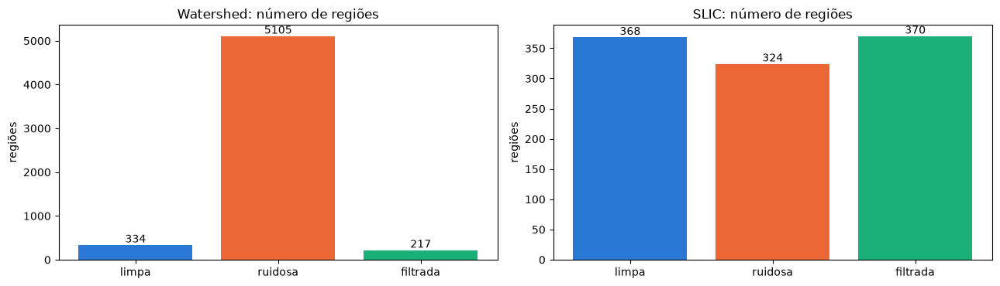

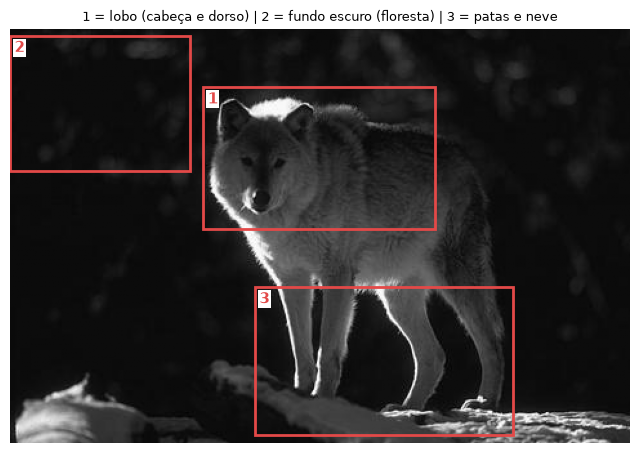

Recorte: lobo (cabeça e dorso)


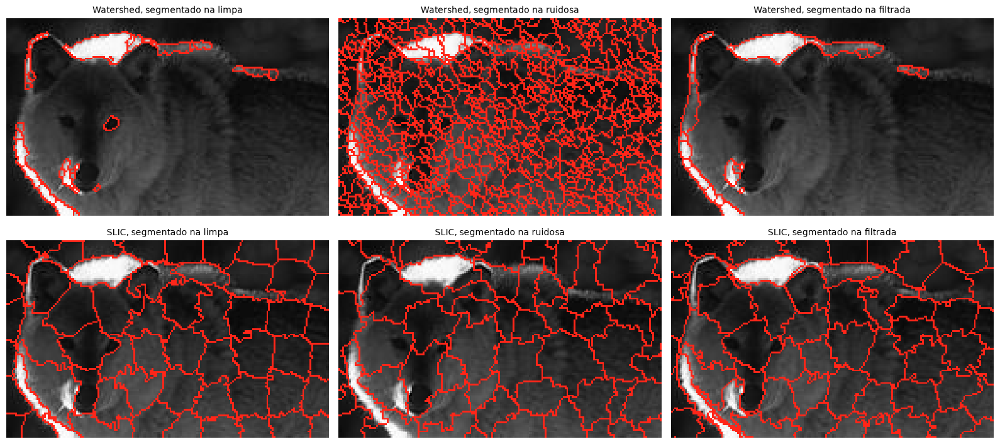

Recorte: fundo escuro (floresta)


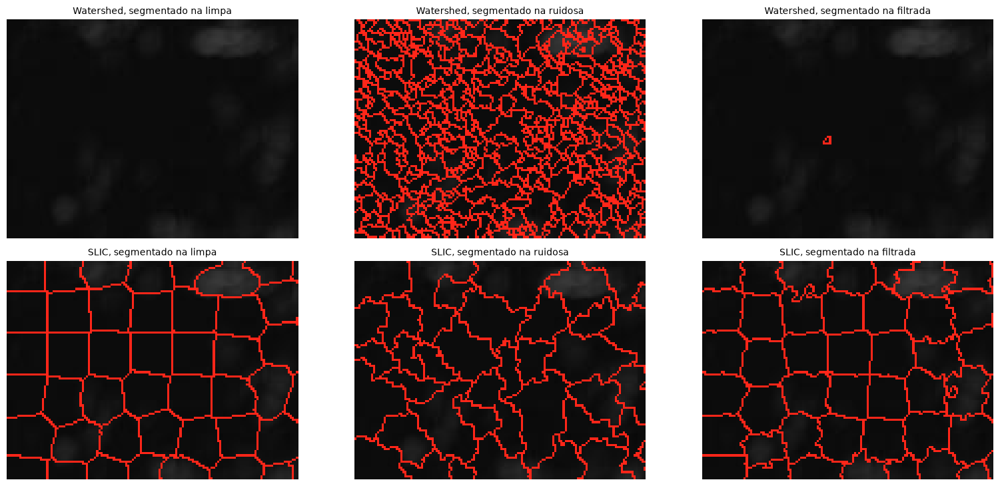

Recorte: patas e neve


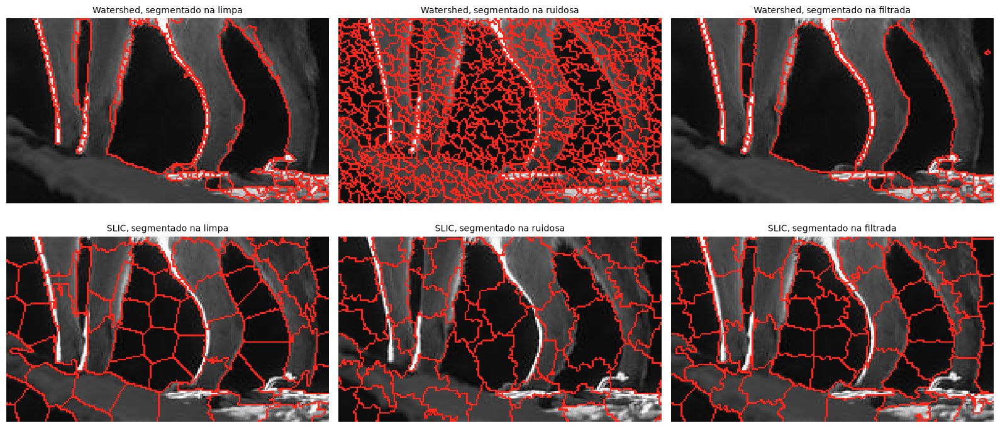

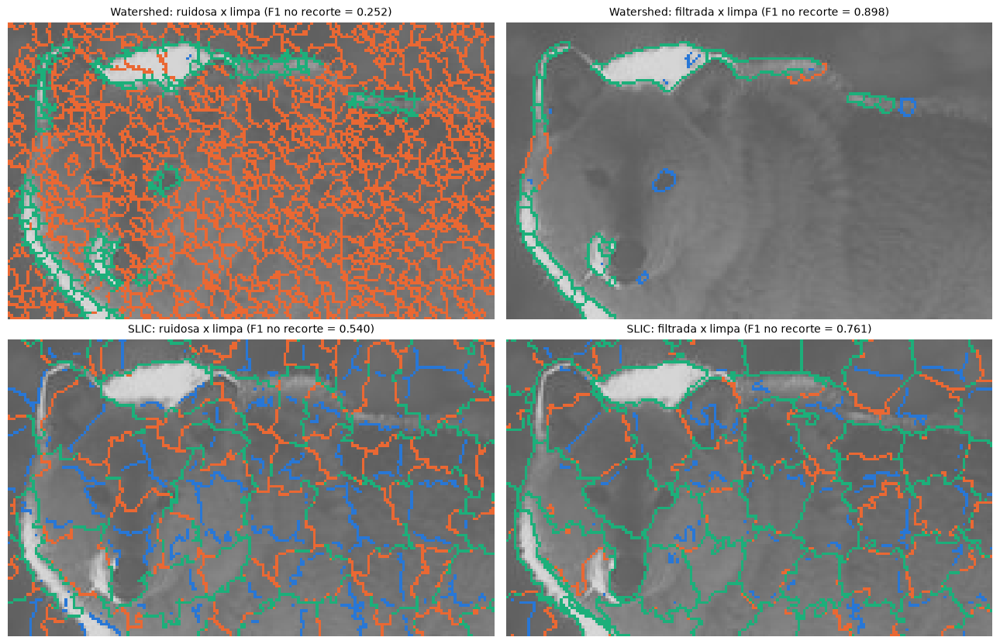

Verde = borda que coincide com a da limpa (até 2 px) | laranja = borda falsa | azul = borda da limpa perdida


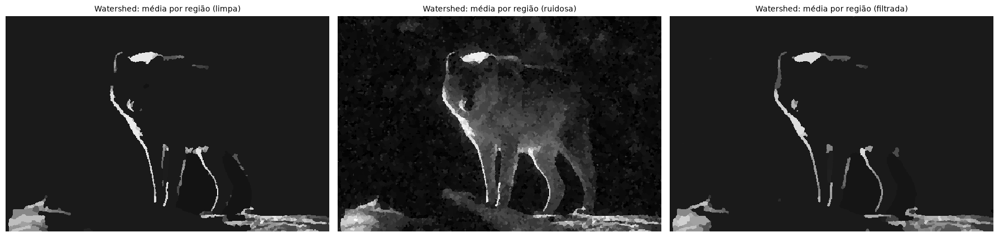

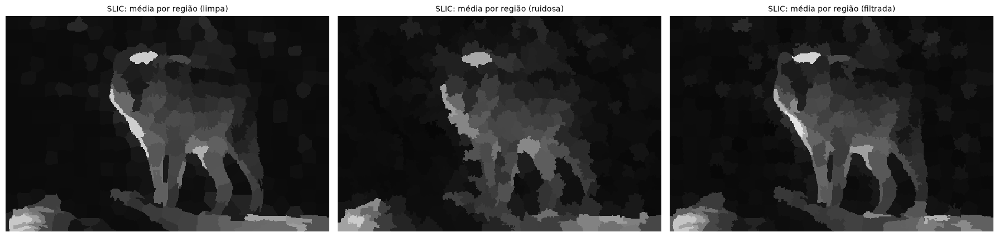

In [20]:
"""ETAPA 6: COMPARAÇÃO (NÚMERO DE REGIÕES, CONTORNO COM O ORIGINAL E ANÁLISE VISUAL)"""
TOLERANCIA = 2   # px: deslocamento máximo para uma borda ainda contar como "a mesma" borda
MICRO = 20       # px: regiões menores que isso são consideradas micro-regiões (supersegmentação)


def f1_bordas(pred, ref, tolerancia=TOLERANCIA):
    """Precisão: fração das bordas obtidas que estão a até `tolerancia` px de uma borda de referência.
    Revocação: fração das bordas de referência que estão a até `tolerancia` px de uma borda obtida.
    A distância de cada pixel até a borda mais próxima vem da transformada de distância euclidiana."""
    precisao = np.mean(distance_transform_edt(~ref)[pred] <= tolerancia)
    revocacao = np.mean(distance_transform_edt(~pred)[ref] <= tolerancia)
    f1 = 2 * precisao * revocacao / (precisao + revocacao) if precisao + revocacao else 0.0
    return precisao, revocacao, f1


def mapa_contornos(pred, ref, fundo, tolerancia=TOLERANCIA):
    """Verde: borda obtida que coincide com a referência | laranja: borda obtida sem correspondente (falsa) |
    azul: borda da referência que não foi encontrada (perdida). Fundo: imagem limpa esmaecida."""
    rgb = np.repeat((0.35 + 0.5 * fundo)[..., None], 3, axis=2)
    perto_ref = distance_transform_edt(~ref) <= tolerancia
    perto_pred = distance_transform_edt(~pred) <= tolerancia
    rgb[ref & ~perto_pred] = (0.16, 0.47, 0.84)
    rgb[pred & ~perto_ref] = (0.92, 0.41, 0.20)
    rgb[pred & perto_ref] = (0.11, 0.69, 0.48)
    return rgb


# --- 6.1 Tabela: número de regiões e contorno em relação à segmentação da imagem original ---
linhas = {}
for (metodo, nome), rot in segmentacoes.items():
    _, areas = np.unique(rot, return_counts=True)
    bordas = bordas_rotulos(rot)
    p, r, f1 = f1_bordas(bordas, bordas_rotulos(segmentacoes[(metodo, 'limpa')]))
    linhas[(metodo, nome)] = {
        'nº de regiões': len(areas),
        'área mediana (px)': np.median(areas),
        f'regiões < {MICRO} px': int(np.sum(areas < MICRO)),
        'pixels de borda (%)': 100 * bordas.mean(),
        'precisão vs limpa': p,
        'revocação vs limpa': r,
        'F1 vs limpa': f1,
    }
tabela = pd.DataFrame.from_dict(linhas, orient='index').rename_axis(['método', 'entrada'])
display(tabela.round(3))

# F1 dos contornos dentro de cada recorte fixo (objeto x fundo x patas e neve), contra o mesmo método na limpa
f1_recortes = {}
for (metodo, nome), rot in segmentacoes.items():
    if nome == 'limpa':
        continue
    ref = bordas_rotulos(segmentacoes[(metodo, 'limpa')])
    pred = bordas_rotulos(rot)
    f1_recortes[(metodo, nome)] = {f'F1 {k}': f1_bordas(recortar(pred, caixa), recortar(ref, caixa))[2]
                                   for k, caixa in RECORTES.items()}
display(pd.DataFrame.from_dict(f1_recortes, orient='index').rename_axis(['método', 'entrada']).round(3))

fig, axs = plt.subplots(1, 2, figsize=(13, 3.8))
for ax, metodo in zip(axs, ('Watershed', 'SLIC')):
    contagens = tabela.loc[metodo, 'nº de regiões']
    barras = ax.bar(contagens.index, contagens.values, color=['#2a78d6', '#eb6834', '#1baf7a'])
    ax.bar_label(barras)
    ax.set_title(f'{metodo}: número de regiões')
    ax.set_ylabel('regiões')
fig.tight_layout()
plt.show()

# --- 6.2 Metodologia visual: recortes fixos, contornos sempre sobre a imagem limpa ---
fig, ax = plt.subplots(figsize=(8, 5.4))
ax.imshow(limpa, cmap='gray', vmin=0, vmax=1)
for k, (nome, (x, y, l, a)) in enumerate(RECORTES.items(), 1):
    ax.add_patch(mpatches.Rectangle((x - .5, y - .5), l, a, fill=False, ec='#e34948', lw=2))
    ax.text(x + 3, y + 3, str(k), color='#e34948', fontsize=11, fontweight='bold', va='top',
            bbox=dict(fc='white', ec='none', pad=1))
ax.set_title(' | '.join(f'{k} = {nome}' for k, nome in enumerate(RECORTES, 1)), fontsize=9)
ax.axis('off')
plt.show()

for nome_recorte, caixa in RECORTES.items():
    imagens, titulos = [], []
    for metodo in ('Watershed', 'SLIC'):
        for nome in ENTRADAS:
            imagens.append(recortar(sobrepor_contornos(limpa, segmentacoes[(metodo, nome)]), caixa))
            titulos.append(f'{metodo}, segmentado na {nome}')
    print(f'Recorte: {nome_recorte}')
    painel(imagens, titulos, 3, figsize=(16, 7.4))

# --- 6.3 Contorno com o original: coincidências, bordas falsas e bordas perdidas ---
nome_recorte = RECORTE_OBJETO
caixa = RECORTES[nome_recorte]
imagens, titulos = [], []
for metodo in ('Watershed', 'SLIC'):
    ref = bordas_rotulos(segmentacoes[(metodo, 'limpa')])
    for nome in ('ruidosa', 'filtrada'):
        pred = bordas_rotulos(segmentacoes[(metodo, nome)])
        imagens.append(recortar(mapa_contornos(pred, ref, limpa), caixa))
        titulos.append(f'{metodo}: {nome} x limpa (F1 no recorte = {f1_recortes[(metodo, nome)]["F1 " + nome_recorte]:.3f})')
painel(imagens, titulos, 2, figsize=(13, 8.4))
print('Verde = borda que coincide com a da limpa (até 2 px) | laranja = borda falsa | azul = borda da limpa perdida')

# --- 6.4 Representação simplificada: cada região com a sua intensidade média ---
for metodo in ('Watershed', 'SLIC'):
    painel([imagem_media_regioes(img, segmentacoes[(metodo, nome)]) for nome, img in ENTRADAS.items()],
           [f'{metodo}: média por região ({nome})' for nome in ENTRADAS], 3, figsize=(18, 4.4))

**Análise dos resultados**

| | Watershed (h = 0,2) | | | SLIC (400, compacidade 0,1) | | |
|---|---:|---:|---:|---:|---:|---:|
| | limpa | ruidosa | filtrada | limpa | ruidosa | filtrada |
| nº de regiões | 334 | 5105 | 217 | 368 | 324 | 370 |
| regiões < 20 px | 225 | 2650 | 88 | 0 | 0 | 0 |
| pixels de borda | 3,0% | 36,6% | 2,6% | 10,8% | 12,1% | 12,0% |
| precisão / revocação vs limpa | — | 0,112 / 0,997 | 0,942 / 0,903 | — | 0,494 / 0,542 | 0,755 / 0,789 |
| F1 vs limpa (imagem inteira) | — | 0,201 | **0,922** | — | 0,517 | **0,771** |
| F1 no recorte do lobo | — | 0,252 | **0,898** | — | 0,540 | **0,761** |
| F1 no recorte do fundo escuro | — | indefinido | indefinido | — | 0,485 | **0,747** |
| F1 no recorte das patas e neve | — | 0,467 | **0,950** | — | 0,566 | **0,772** |

**Watershed**

- **Limpa (a referência):** 334 regiões, mas 225 delas têm menos de 20 px, e só 3,0% dos pixels são borda. A imagem média por região mostra o que sobra: as estruturas claras e finas (o topo da cabeça e a linha de luz do rosto, do peito e das pernas), partes das pernas e a neve. O corpo e o rosto do lobo estão na mesma região do fundo, pelo vazamento discutido na etapa 5.
- **Ruidosa:** o ruído multiplica as regiões por 15 e os pixels de borda por 12 (36,6%). A revocação de 0,997 é enganosa: com tantas bordas, quase toda borda verdadeira tem alguma a até 2 px. A precisão de 0,112 mostra que 89% das bordas são falsas (laranja em todo o recorte do lobo no mapa de contornos).
- **Filtrada:** a precisão sobe para 0,942, as micro-regiões caem de 2650 para 88 e o F1 vai de 0,201 para **0,922**. Nos recortes, o lobo vai de 0,252 para **0,898**, e as patas e a neve, de 0,467 para **0,950**. O resultado praticamente reproduz o da limpa (ver a imagem média por região).
- **Recorte do fundo escuro:** a limpa não tem nenhuma borda ali, por isso o F1 fica indefinido (NaN). Nesse caso, qualquer borda é falsa, e a figura do recorte mostra a diferença diretamente: na ruidosa, cerca de um terço dos pixels do recorte vira borda; na filtrada, sobra só um contorno minúsculo.
- **Custo:** a filtrada termina com menos regiões que a própria limpa (217 contra 334), e a revocação de 0,903 indica que cerca de 10% das bordas da limpa se perderam. São bacias pequenas e reais que o borramento aterrou, como a região em volta do olho (azul no mapa de contornos) e detalhes da neve.

**SLIC**

- **Contagem:** com a fusão pela maior fronteira, o número de superpixels fica estável nas três entradas (368, 324 e 370). No SLIC, o efeito do ruído **não está na contagem**.
- **Contornos na ruidosa:** precisão e revocação caem juntas (0,494 / 0,542). Os superpixels continuam do mesmo tamanho, mas as fronteiras ficam serrilhadas e deslocadas: parte acompanha o ruído (laranja), e parte dos contornos reais se perde (azul). No fundo escuro, a grade quase regular da limpa vira um conjunto de regiões sinuosas.
- **Filtrada:** o F1 sobe de 0,517 para **0,771** e melhora **em todos os recortes**: lobo de 0,540 para 0,761, fundo escuro de 0,485 para 0,747 e patas e neve de 0,566 para 0,772. Com o ruído atenuado, a distância de intensidade volta a refletir a imagem, e a grade regular volta a aparecer no fundo.

**Comparação entre os métodos**

- **Watershed:** segue as bordas fortes pixel a pixel (a linha de luz, as pernas e a neve), mas depende de bordas fechadas. Com os marcadores h-mínimos, ele vaza pelo lado em sombra e não representa o lobo como objeto. O número de regiões depende muito da entrada (de 217 a 5105).
- **SLIC:** cada superpixel só disputa os pixels de uma janela 2S × 2S, então não há vazamento de longo alcance. Na imagem média por região, a silhueta do lobo, inclusive o lado em sombra, aparece nas três entradas. Em troca, o SLIC divide o lobo e o fundo em centenas de regiões de tamanho parecido: é uma supersegmentação por construção, útil como representação simplificada, e não como segmentação do objeto.
- **Efeito do ruído:**
  - No Watershed, aparece como **mais regiões** (15 vezes mais).
  - No SLIC, como **contornos piores com quase a mesma contagem**.
  - Nos dois casos, a filtragem na frequência recuperou boa parte da qualidade.

**Problemas encontrados e limitações**

1. **O Watershed clássico não serve para esta imagem**, mesmo sem ruído: a limpa vira 7099 regiões, com mediana de 13 px. Foi preciso controlar os marcadores (h-mínima), e o resultado passa a depender do h.
2. **Vazamento pelo lado em sombra.** Nenhum h testado separa o lobo inteiro do fundo na limpa. Marcadores definidos por outro critério (por exemplo, um por objeto, a partir de uma limiarização) ou um relevo que reforce as bordas fracas seriam os próximos passos.
3. **O h interage com o filtro.** O borramento baixa as cristas do gradiente, então o mesmo h "aterra" mais bacias na filtrada: em h = 0,8, a filtrada vira 2 regiões, contra 66 da limpa. Filtro e segmentador precisam ser ajustados juntos.
4. **O filtro foi escolhido pelo PSNR, não pela segmentação.** O SSIM preferia um corte bem menor (0,06), que limparia mais o fundo, mas borraria as bordas de que os dois segmentadores dependem.
5. **O F1 com tolerância favorece segmentações densas:** a revocação de 0,997 da ruidosa no Watershed só faz sentido junto com a precisão.
6. **A referência é a segmentação da limpa, não um gabarito humano:** o F1 mede o quanto ruído e filtro *alteram* a segmentação, não se ela está *certa*. Nesta imagem isso pesa: o F1 de 0,922 do Watershed significa reproduzir uma segmentação que não isola o lobo. As 7 segmentações humanas do BSDS (de 4 a 9 regiões) seriam a referência ideal.
7. **O SLIC próprio não é idêntico ao do skimage** (centros movidos pelo gradiente, outra estratégia de conectividade). Os dois concordam em cerca de 85% dos pixels na limpa e 82% na filtrada, e bem menos na ruidosa (57%).
8. **Desempenho:** a rotulagem, a inundação e a conectividade percorrem os pixels em Python puro. Cada segmentação leva segundos, contra milissegundos do código compilado do scikit-image. A etapa 5 inteira é a parte mais lenta do notebook.

**Conclusão:** a filtragem gaussiana na frequência ($f_c$ = 0,16, escolhida pelo PSNR e a um passo do corte estimado pelo espectro) melhorou os dois segmentadores em relação à imagem ruidosa:

- **Watershed:** F1 de 0,201 para 0,922 (de 0,252 para 0,898 no recorte do lobo), e as regiões caem de 5105 para 217.
- **SLIC:** F1 de 0,517 para 0,771, com melhora em todos os recortes.

O ganho é maior no fundo escuro, onde o ruído domina: ali, a filtrada praticamente não tem bordas falsas. O limite do resultado não vem do ruído, e sim do próprio Watershed, que mesmo na imagem limpa não fecha o contorno do lobo no lado em sombra.

# Parte 2 – Segmentação Morfológica e Gap-Filling para Contagem de Células

A segunda parte do trabalho foca na segmentação morfológica clássica, com aplicação direta
em imagens de microscopia celular. Ao contrário da abordagem anterior, aqui não são utilizados
algoritmos de agrupamento ou segmentadores tradicionais, mas sim operações morfológicas para
processar diretamente uma imagem binária.

A partir de imagens reais de núcleos celulares — como as fornecidas pelo dataset BBBC006,
que contém núcleos com buracos internos e fragmentações de contorno — aplicam-se técnicas como
fechamento morfológico, preenchimento de buracos (gap-filling) e remoção de ruídos.
Estas operações visam corrigir falhas comuns que ocorrem após a limiarização, como buracos não
representativos dentro das células ou contornos incompletos que dificultam a contagem precisa dos
núcleos.

Por fim, é realizada a rotulagem de componentes conectados, permitindo a contagem automatizada
de células antes e depois do pós-processamento morfológico. Esta comparação evidencia a importância
das operações morfológicas na segmentação de imagens biomédicas e sua influência direta na
precisão de contagem de estruturas celulares.

**Nota experimental:** a Imagem 1 é uma máscara artificial binária de círculos; a Imagem 2 mostra um esfregaço com hemácias e outras células. A foto do lobo `42078.jpg` pertence apenas à Parte 1.

## Etapas

1. Pré-processamento
    - Ler a imagem em tons de cinza. Usar as imagens: [Imagem 1](https://github.com/VielF/ColabProjects/blob/main/dataset/OperacaoMorfologia/gap-region-filling.tif) e [Imagem 2](https://github.com/VielF/ColabProjects/blob/main/dataset/OperacaoMorfologia/002f20ad-2ace-499c-9335-c9080bc3e6b5.png).
        
    - Aplicar filtro Gaussiano leve (opcional) para reduzir ruído.


Arquivos locais utilizados: `data/gap-region-filling.tif` e `data/002f20ad-2ace-499c-9335-c9080bc3e6b5.png`.

In [21]:
from pathlib import Path
from collections import deque

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

CONFIG = {
    "Imagem 1": {"inverter": False, "raio_fechamento": 2, "raio_abertura": 1, "area_minima": 200},
    "Imagem 2": {"inverter": True, "raio_fechamento": 2, "raio_abertura": 1, "area_minima": 200},
}


NOMES_ARQUIVOS = ["gap-region-filling.tif", "002f20ad-2ace-499c-9335-c9080bc3e6b5.png"]

EXTENSOES = {".png", ".jpg", ".jpeg", ".tif", ".tiff", ".bmp"}

def ler_cinza_8bits(caminho):
    """Lê PNG/JPEG/TIFF e converte manualmente para escala de cinza de 0 a 255."""
    dados = np.asarray(Image.open(caminho))
    if dados.ndim == 2:
        cinza = dados.astype(np.float64)
    elif dados.ndim == 3 and dados.shape[2] >= 3:
        canais = dados[:, :, :3].astype(np.float64)
        cinza = 0.299 * canais[:, :, 0] + 0.587 * canais[:, :, 1] + 0.114 * canais[:, :, 2]
    elif dados.ndim == 3 and dados.shape[2] == 1:
        cinza = dados[:, :, 0].astype(np.float64)
    else:
        raise ValueError(f"Formato de imagem não suportado: {dados.shape}")

    if not np.all(np.isfinite(cinza)):
        raise ValueError("A imagem contém valores NaN/infinitos.")
    # Percentis calculados manualmente por interpolação linear; np.sort só ordena os dados.
    def percentil_manual(valores, porcentagem):
        ordenados = np.sort(valores.reshape(-1))
        posicao = (ordenados.size - 1) * porcentagem / 100.0
        indice = int(posicao)
        fracao = posicao - indice
        if indice + 1 == ordenados.size:
            return float(ordenados[indice])
        return float(ordenados[indice] + fracao * (ordenados[indice + 1] - ordenados[indice]))

    menor = percentil_manual(cinza, 0.5)
    maior = percentil_manual(cinza, 99.5)
    if maior <= menor:
        menor, maior = float(cinza.min()), float(cinza.max())
    if maior <= menor:
        return np.zeros(cinza.shape, dtype=np.uint8)

    # Reescala e limites implementados pela fórmula, sem np.clip.
    normalizada = (cinza - menor) * 255.0 / (maior - menor)
    normalizada[normalizada < 0.0] = 0.0
    normalizada[normalizada > 255.0] = 255.0
    saida = np.zeros(cinza.shape, dtype=np.uint8)
    for y in range(cinza.shape[0]):
        for x in range(cinza.shape[1]):
            saida[y, x] = round(float(normalizada[y, x]))
    return saida


def otsu_manual(cinza):
    """Encontra limiar global maximizando a variância interclasses, sem cv2.threshold."""
    if cinza.ndim != 2 or cinza.dtype != np.uint8:
        raise ValueError("Otsu espera imagem 2D uint8.")
    hist = np.bincount(cinza.ravel(), minlength=256)
    total = cinza.size
    soma_total = sum(i * int(hist[i]) for i in range(256))
    peso_fundo = 0
    soma_fundo = 0
    maior_variancia = -1.0
    melhor_limiar = 0
    for t in range(256):
        peso_fundo += int(hist[t])
        if peso_fundo == 0:
            continue
        peso_objeto = total - peso_fundo
        if peso_objeto == 0:
            break
        soma_fundo += t * int(hist[t])
        media_fundo = soma_fundo / peso_fundo
        media_objeto = (soma_total - soma_fundo) / peso_objeto
        variancia = peso_fundo * peso_objeto * (media_fundo - media_objeto) ** 2
        if variancia > maior_variancia:
            maior_variancia = variancia
            melhor_limiar = t
    return melhor_limiar


def binarizar_manual(cinza, limiar, inverter=False):
    """True representa o primeiro plano (núcleos)."""
    return (cinza <= limiar) if inverter else (cinza > limiar)

2. Limiarização
    - Aplicar limiarização global ou Otsu para segmentar o foreground (núcleos).
    - Resultado: imagem binária com regiões de interesse.

Imagem 1: gap-region-filling.tif | limiar de Otsu=0 | 35.3% primeiro plano
Imagem 2: 002f20ad-2ace-499c-9335-c9080bc3e6b5.png | limiar de Otsu=161 | 24.0% primeiro plano


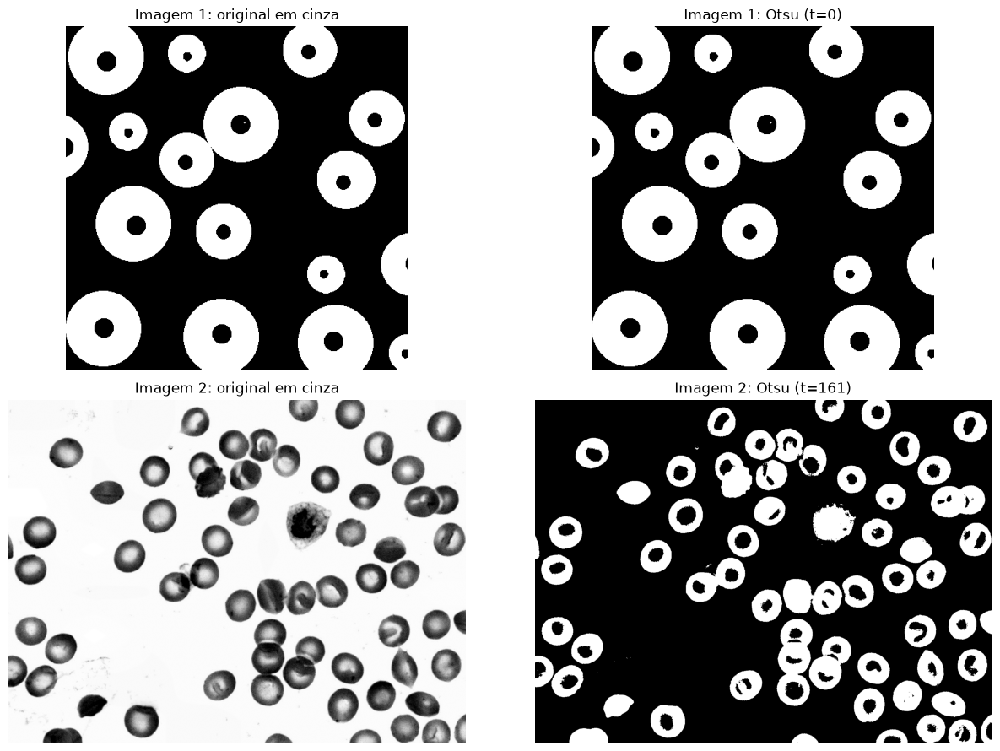

In [22]:
# Limiarização global de Otsu — a polaridade correta depende da imagem.
PASTA_M22 = Path("data") if Path("data").is_dir() else Path("M2-2") / "data"
IMAGENS_M22 = {}
for nome, arquivo in zip(CONFIG, NOMES_ARQUIVOS):
    caminho = PASTA_M22 / arquivo
    if not caminho.exists():
        raise FileNotFoundError(f"Imagem obrigatória não encontrada: {caminho}")
    cinza = ler_cinza_8bits(caminho)
    limiar = otsu_manual(cinza)
    mascara = binarizar_manual(cinza, limiar, CONFIG[nome]["inverter"])
    IMAGENS_M22[nome] = {"caminho": caminho, "cinza": cinza, "limiar": limiar, "binaria": mascara}
    print(f"{nome}: {arquivo} | limiar de Otsu={limiar} | {100*mascara.mean():.1f}% primeiro plano")

fig, axs = plt.subplots(2, 2, figsize=(13, 9))
for linha, (nome, resultado) in enumerate(IMAGENS_M22.items()):
    axs[linha, 0].imshow(resultado["cinza"], cmap="gray", vmin=0, vmax=255)
    axs[linha, 0].set_title(f"{nome}: original em cinza")
    axs[linha, 1].imshow(resultado["binaria"], cmap="gray")
    axs[linha, 1].set_title(f"{nome}: Otsu (t={resultado['limiar']})")
    for ax in axs[linha]: ax.axis("off")
plt.tight_layout()
plt.show()

3. Análise das falhas
- Visualizar que algumas células:
    1. Têm buracos internos (núcleo oco).
    2. Estão quebradas ou parcialmente conectadas.

In [23]:
# Diagnóstico visual após a limiarização.
# Na imagem 1, os círculos brancos têm centros pretos, correspondendo a buracos internos.
# Na imagem 2, centros claros e células sobrepostas provocam máscaras fragmentadas/ocas.
# O gráfico permite comparar a máscara que será enviada à morfologia.
for nome, dados in IMAGENS_M22.items():
    m = dados["binaria"]
    print(f"{nome}: formato={m.shape}, primeiro plano={int(m.sum())} px; "
          "buracos e conexões serão corrigidos nas próximas células.")

Imagem 1: formato=(512, 512), primeiro plano=92581 px; buracos e conexões serão corrigidos nas próximas células.
Imagem 2: formato=(1200, 1600), primeiro plano=460752 px; buracos e conexões serão corrigidos nas próximas células.


4. Operações morfológicas
    - Fechamento morfológico para conectar fragmentos.
    - Preenchimento de buracos (gap-filling)
    - Abertura para remover pequenas partículas ou ruído.

In [24]:
def offsets_disco(raio):
    if not isinstance(raio, int) or raio < 0:
        raise ValueError("O raio deve ser inteiro não negativo.")
    return [(dy, dx)
            for dy in range(-raio, raio + 1)
            for dx in range(-raio, raio + 1)
            if dy * dy + dx * dx <= raio * raio]


def dilatacao_manual(mascara, raio=1):
    """Dilatação binária implementada por deslocamentos e OU lógico."""
    mascara = np.asarray(mascara, dtype=bool)
    h, w = mascara.shape
    padded = np.pad(mascara, raio, mode="constant", constant_values=False)
    saida = np.zeros_like(mascara)
    for dy, dx in offsets_disco(raio):
        saida |= padded[raio + dy:raio + dy + h, raio + dx:raio + dx + w]
    return saida


def erosao_manual(mascara, raio=1):
    """Erosão binária implementada por deslocamentos e E lógico."""
    mascara = np.asarray(mascara, dtype=bool)
    h, w = mascara.shape
    padded = np.pad(mascara, raio, mode="constant", constant_values=False)
    saida = np.ones_like(mascara)
    for dy, dx in offsets_disco(raio):
        saida &= padded[raio + dy:raio + dy + h, raio + dx:raio + dx + w]
    return saida


def fechamento_manual(mascara, raio=2):
    return erosao_manual(dilatacao_manual(mascara, raio), raio)


def abertura_manual(mascara, raio=1):
    return dilatacao_manual(erosao_manual(mascara, raio), raio)


def preencher_buracos_manual(mascara):
    """Flood-fill (BFS, 4 vizinhos) do fundo externo; buracos internos são preenchidos."""
    mascara = np.asarray(mascara, dtype=bool)
    h, w = mascara.shape
    fundo = ~mascara
    externo = np.zeros_like(mascara)
    fila = deque()

    def inserir(y, x):
        if fundo[y, x] and not externo[y, x]:
            externo[y, x] = True
            fila.append((y, x))

    for x in range(w):
        inserir(0, x)
        inserir(h - 1, x)
    for y in range(h):
        inserir(y, 0)
        inserir(y, w - 1)

    vizinhos4 = ((-1, 0), (1, 0), (0, -1), (0, 1))
    while fila:
        y, x = fila.popleft()
        for dy, dx in vizinhos4:
            ny, nx = y + dy, x + dx
            if 0 <= ny < h and 0 <= nx < w and fundo[ny, nx] and not externo[ny, nx]:
                externo[ny, nx] = True
                fila.append((ny, nx))

    buracos = fundo & ~externo
    return mascara | buracos, buracos

5. Contagem de objetos (Implementar o seu próprio código – sem pré-pronto)
    - Implementar o seu próprio algoritmo de contagem de objetos automático.
    - Comparar a contagem de células antes e depois do gap-filling.

TESTES OK | Antes: 4 componentes | Depois: 2 componentes


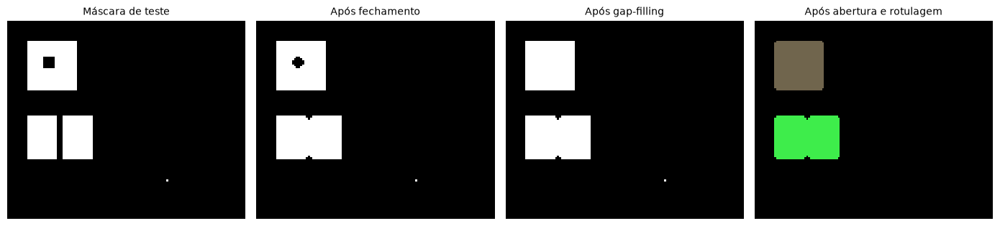

Imagens selecionadas: ['data\\gap-region-filling.tif', 'data\\002f20ad-2ace-499c-9335-c9080bc3e6b5.png']
Imagem 1 (gap-region-filling.tif) | Otsu: 0 | Antes: 16 | Depois: 16
Imagem 2 (002f20ad-2ace-499c-9335-c9080bc3e6b5.png) | Otsu: 161 | Antes: 58 | Depois: 57


In [25]:
def rotular_e_contar_manual(mascara, area_minima=1):
    """Rotulagem BFS-8 sem funções prontas. Retorna rótulos, componentes e total bruto."""
    if int(area_minima) < 1:
        raise ValueError("area_minima deve ser >= 1")
    mascara = np.asarray(mascara, dtype=bool)
    if mascara.ndim != 2:
        raise ValueError("Esperada máscara 2D")
    h, w = mascara.shape
    rotulos_brutos = np.zeros((h, w), dtype=np.int32)
    vizinhos8 = [(dy, dx) for dy in (-1, 0, 1) for dx in (-1, 0, 1) if dy or dx]
    areas = []
    centroides = []
    proximo_bruto = 0

    for y in range(h):
        for x in range(w):
            if not mascara[y, x] or rotulos_brutos[y, x] != 0:
                continue
            proximo_bruto += 1
            fila = deque([(y, x)])
            rotulos_brutos[y, x] = proximo_bruto
            area, soma_y, soma_x = 0, 0, 0
            while fila:
                cy, cx = fila.popleft()
                area += 1
                soma_y += cy
                soma_x += cx
                for dy, dx in vizinhos8:
                    ny, nx = cy + dy, cx + dx
                    if (0 <= ny < h and 0 <= nx < w and mascara[ny, nx]
                            and rotulos_brutos[ny, nx] == 0):
                        rotulos_brutos[ny, nx] = proximo_bruto
                        fila.append((ny, nx))
            areas.append(area)
            centroides.append((soma_y / area, soma_x / area))

    # Mapeia só componentes de área suficiente para IDs consecutivos (1,2,...).
    remapeamento = np.zeros(proximo_bruto + 1, dtype=np.int32)
    componentes = []
    for id_bruto, (area, (cy, cx)) in enumerate(zip(areas, centroides), start=1):
        if area >= area_minima:
            id_final = len(componentes) + 1
            remapeamento[id_bruto] = id_final
            componentes.append({"id": id_final, "area": int(area), "centro_y": cy, "centro_x": cx})
    rotulos = remapeamento[rotulos_brutos]
    return rotulos, componentes, proximo_bruto


def colorir_rotulos(rotulos, seed=11):
    """Gera uma imagem RGB para visualizar cada componente com cor diferente."""
    n = int(rotulos.max())
    rng = np.random.default_rng(seed)
    cores = np.zeros((n + 1, 3), dtype=np.uint8)
    if n:
        cores[1:] = rng.integers(50, 256, size=(n, 3), dtype=np.uint8)
    return cores[rotulos]

# Testes de propriedades de operações morfológicas.
teste = np.zeros((9, 9), dtype=bool)
teste[4, 4] = True
assert dilatacao_manual(teste, 1).sum() == 5, "Dilatação de disco raio 1 deveria ocupar 5 pixels"
assert not erosao_manual(teste, 1).any(), "Erosão deve apagar pixel isolado"
assert np.array_equal(dilatacao_manual(teste, 0), teste)
assert np.array_equal(erosao_manual(teste, 0), teste)

# Cenário controlado com um buraco, um núcleo fragmentado e um ruído isolado.
sintetica = np.zeros((100, 120), dtype=bool)
sintetica[10:35, 10:35] = True
sintetica[18:24, 18:24] = False  # buraco fechado no interior
sintetica[48:70, 10:25] = True   # fragmento A
sintetica[48:70, 28:43] = True   # fragmento B (lacuna de 3 px)
sintetica[80, 80] = True         # ruído isolado

rot_pre, comps_pre, bruto_pre = rotular_e_contar_manual(sintetica, 1)
fec = fechamento_manual(sintetica, 2)
preenchida, buracos = preencher_buracos_manual(fec)
final = abertura_manual(preenchida, 1)
rot_pos, comps_pos, bruto_pos = rotular_e_contar_manual(final, 1)

assert len(comps_pre) == 4, f"Esperados 4 componentes antes; encontrados {len(comps_pre)}"
assert len(comps_pos) == 2, f"Esperados 2 componentes depois; encontrados {len(comps_pos)}"
assert buracos.sum() > 0, "Gap-filling deveria identificar buraco interno"
assert final[20, 20], "O buraco deveria estar preenchido"
assert not final[80, 80], "O ruído isolado deveria ter sido removido"
print(f"TESTES OK | Antes: {len(comps_pre)} componentes | Depois: {len(comps_pos)} componentes")

fig, ax = plt.subplots(1, 4, figsize=(14, 3.4))
for a, dados, titulo in zip(ax,
                           [sintetica, fec, preenchida, colorir_rotulos(rot_pos)],
                           ["Máscara de teste", "Após fechamento", "Após gap-filling", "Após abertura e rotulagem"]):
    a.imshow(dados, cmap="gray" if dados.ndim == 2 else None, interpolation="nearest")
    a.set_title(titulo, fontsize=10)
    a.axis("off")
plt.tight_layout()
plt.show()

def localizar_dados():
    # Os caminhos são relativos ao ambiente de execução e compatíveis com o README do grupo.
    candidatas = [Path("data"), Path("M2-2") / "data"]
    for pasta in candidatas:
        if pasta.is_dir() and any(p.suffix.lower() in EXTENSOES for p in pasta.iterdir()):
            return pasta
    return None


def descobrir_arquivos(pasta):
    if pasta is None:
        return []
    disponiveis = sorted((p for p in pasta.iterdir() if p.is_file() and p.suffix.lower() in EXTENSOES),
                         key=lambda p: p.name.lower())
    if NOMES_ARQUIVOS is not None:
        if len(NOMES_ARQUIVOS) != 2:
            raise ValueError("NOMES_ARQUIVOS deve conter exatamente dois nomes.")
        escolhidos = [pasta / nome for nome in NOMES_ARQUIVOS]
        faltantes = [p.name for p in escolhidos if not p.is_file()]
        if faltantes:
            raise FileNotFoundError(f"Arquivos não encontrados em {pasta}: {faltantes}")
        return escolhidos
    if len(disponiveis) == 2:
        return disponiveis
    if len(disponiveis) > 2:
        print("Há mais de duas imagens em data/. Defina NOMES_ARQUIVOS na primeira célula.")
        print("Arquivos encontrados:", [p.name for p in disponiveis])
    return []


def executar_pipeline(caminho, configuracao):
    cinza = ler_cinza_8bits(caminho)
    limiar = otsu_manual(cinza)
    binaria = binarizar_manual(cinza, limiar, configuracao["inverter"])
    rot_antes, componentes_antes, bruto_antes = rotular_e_contar_manual(binaria, configuracao["area_minima"])

    fechada = fechamento_manual(binaria, configuracao["raio_fechamento"])
    preenchida, buracos = preencher_buracos_manual(fechada)
    aberta = abertura_manual(preenchida, configuracao["raio_abertura"])
    rot_depois, componentes_depois, bruto_depois = rotular_e_contar_manual(aberta, configuracao["area_minima"])
    mascara_final = rot_depois > 0

    return {
        "arquivo": caminho.name,
        "cinza": cinza,
        "limiar": limiar,
        "binaria": binaria,
        "fechada": fechada,
        "preenchida": preenchida,
        "buracos": buracos,
        "aberta": aberta,
        "mascara_final": mascara_final,
        "rot_antes": rot_antes,
        "rot_depois": rot_depois,
        "componentes_antes": componentes_antes,
        "componentes_depois": componentes_depois,
        "bruto_antes": bruto_antes,
        "bruto_depois": bruto_depois,
        "contagem_antes": len(componentes_antes),
        "contagem_depois": len(componentes_depois),
        "area_minima": configuracao["area_minima"],
    }


pasta_dados = localizar_dados()
arquivos_entrada = descobrir_arquivos(pasta_dados)
RESULTADOS = []
if len(arquivos_entrada) != 2:
    print("FALTAM IMAGENS REAIS: adicione Imagem 1 e Imagem 2 à pasta M2-2/data/ e execute novamente.")
    print("A execução sintética anterior valida o código, mas NÃO substitui o experimento obrigatório.")
else:
    print("Imagens selecionadas:", [str(p) for p in arquivos_entrada])
    for (nome, configuracao), caminho in zip(CONFIG.items(), arquivos_entrada):
        resultado = executar_pipeline(caminho, configuracao)
        resultado["nome"] = nome
        RESULTADOS.append(resultado)
        print(f"{nome} ({caminho.name}) | Otsu: {resultado['limiar']} | "
              f"Antes: {resultado['contagem_antes']} | Depois: {resultado['contagem_depois']}")

6. Visualização e Resultados
    - Apresentar imagens em:
        1. Original
        2. Após limiarização
        3. Após morfologia
        4. Rótulos coloridos de cada célula

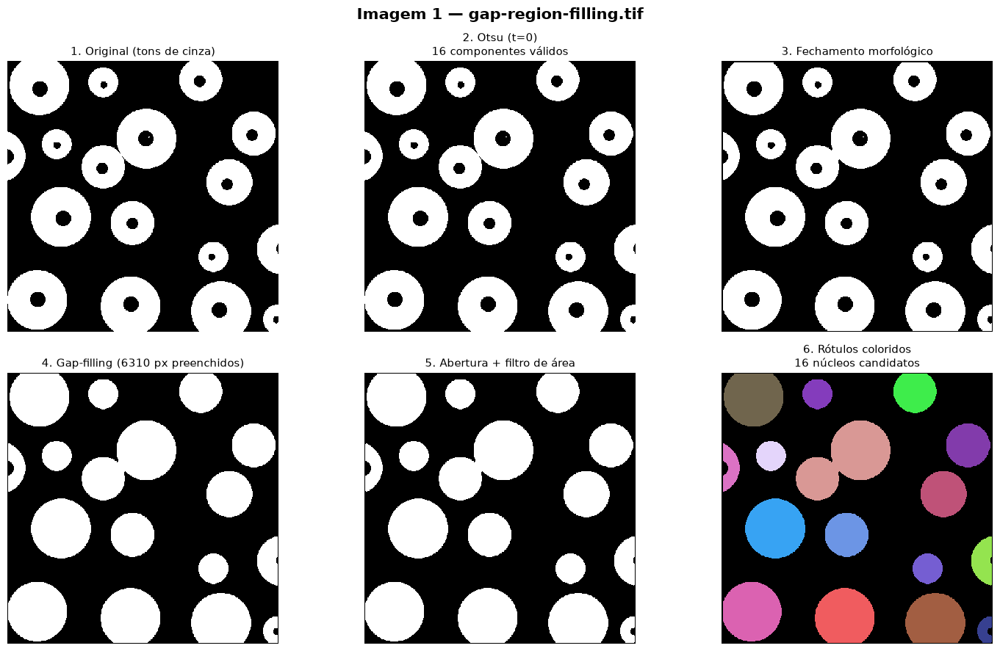

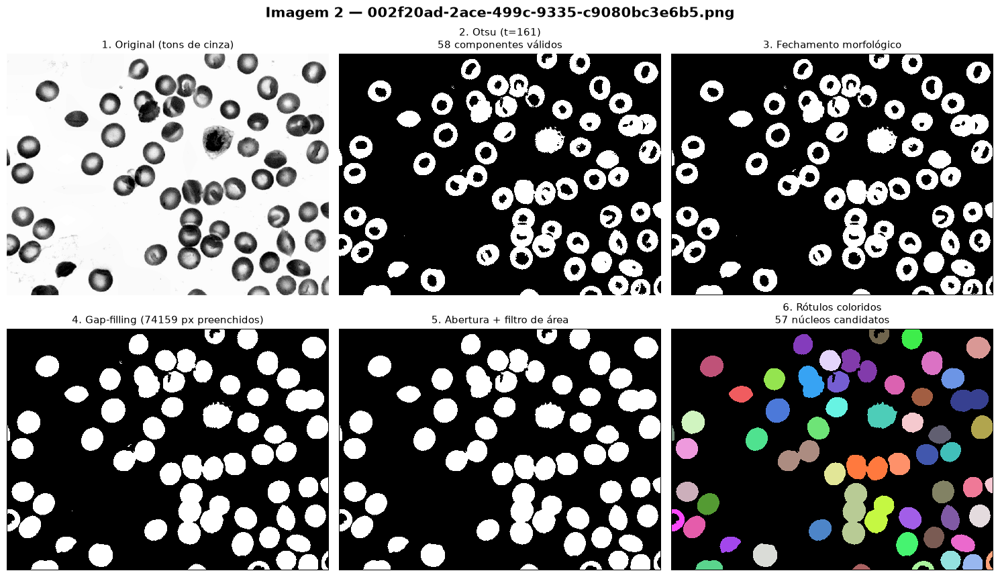


COMPARAÇÃO QUANTITATIVA (componentes conectados)
Imagem        Brutos antes  Válidos antes  Brutos depois  Válidos depois   Diferença
Imagem 1                17             16             16              16          +0
Imagem 2               211             58             60              57          -1


In [26]:
def mostrar_resultado(r):
    fig, ax = plt.subplots(2, 3, figsize=(15, 9))
    fig.suptitle(f"{r['nome']} — {r['arquivo']}", fontsize=15, fontweight="bold")
    paineis = [
        (r["cinza"], "1. Original (tons de cinza)", "gray"),
        (r["binaria"], f"2. Otsu (t={r['limiar']})\n{r['contagem_antes']} componentes válidos", "gray"),
        (r["fechada"], "3. Fechamento morfológico", "gray"),
        (r["preenchida"], f"4. Gap-filling ({int(r['buracos'].sum())} px preenchidos)", "gray"),
        (r["mascara_final"], "5. Abertura + filtro de área", "gray"),
        (colorir_rotulos(r["rot_depois"]), f"6. Rótulos coloridos\n{r['contagem_depois']} núcleos candidatos", None),
    ]
    for a, (img, titulo, cmap) in zip(ax.flat, paineis):
        a.imshow(img, cmap=cmap, interpolation="nearest")
        a.set_title(titulo, fontsize=11)
        a.axis("off")
    plt.tight_layout()
    plt.show()

for resultado in RESULTADOS:
    mostrar_resultado(resultado)

if RESULTADOS:
    print("\nCOMPARAÇÃO QUANTITATIVA (componentes conectados)")
    print(f"{'Imagem':<12} {'Brutos antes':>13} {'Válidos antes':>14} {'Brutos depois':>14} {'Válidos depois':>15} {'Diferença':>11}")
    for r in RESULTADOS:
        diferenca = r["contagem_depois"] - r["contagem_antes"]
        print(f"{r['nome']:<12} {r['bruto_antes']:>13} {r['contagem_antes']:>14} "
              f"{r['bruto_depois']:>14} {r['contagem_depois']:>15} {diferenca:>+11}")
else:
    print("Tabela e painéis das imagens reais indisponíveis até a inclusão dos dois arquivos.")


### Comparação quantitativa — gráficos para o relatório e apresentação

Além dos painéis visuais obrigatórios, os gráficos abaixo sintetizam **três observações distintas**:

1. **Contagem de componentes válidos** antes e depois da morfologia, com o mesmo filtro de área mínima em ambas as etapas.
2. **Componentes descartados pelo filtro de área**, mostrando o impacto sobre pequenos fragmentos/ruídos. O número de objetos brutos não equivale à quantidade real de células.
3. **Fração da imagem ocupada pelo primeiro plano** em cada operação, evidenciando que preencher buracos modifica a máscara mesmo quando a contagem não muda.

**Importante:** esses gráficos descrevem o comportamento do algoritmo, mas não medem acurácia. Para medir precisão seria necessária uma contagem manual de referência das células visíveis.

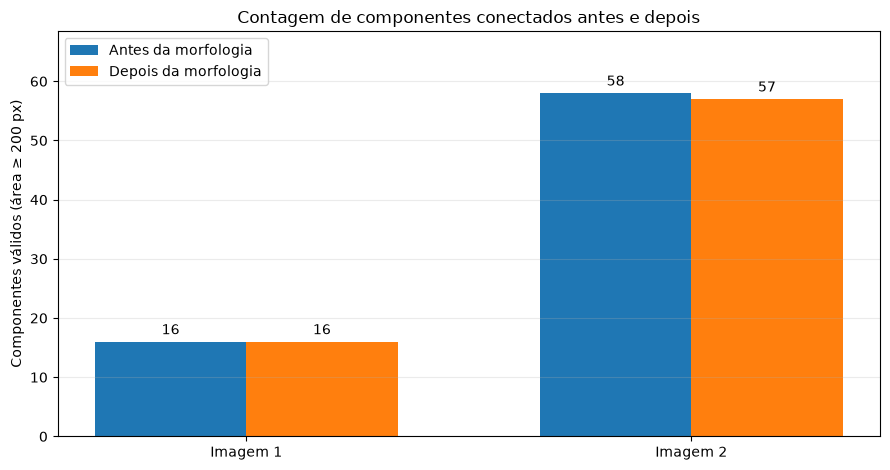

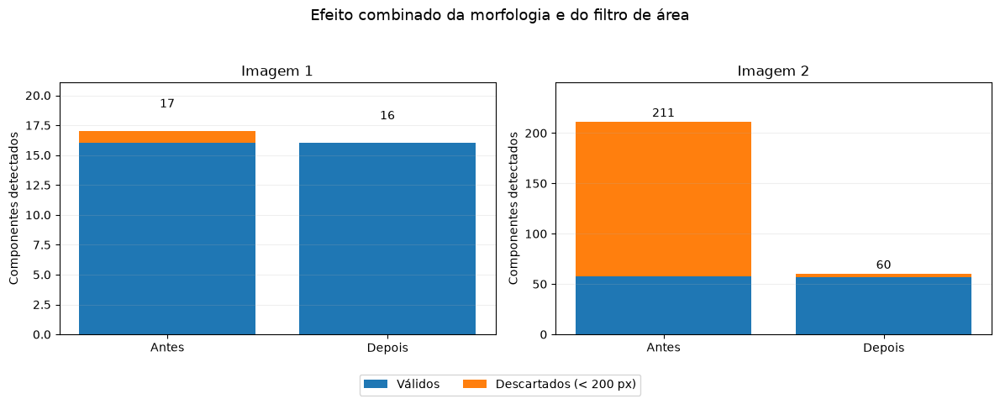

Imagem 1: ocupação por etapa (%) = 35.32, 34.97, 37.38, 37.38, 37.38
Imagem 2: ocupação por etapa (%) = 24.00, 24.19, 28.05, 28.03, 28.02


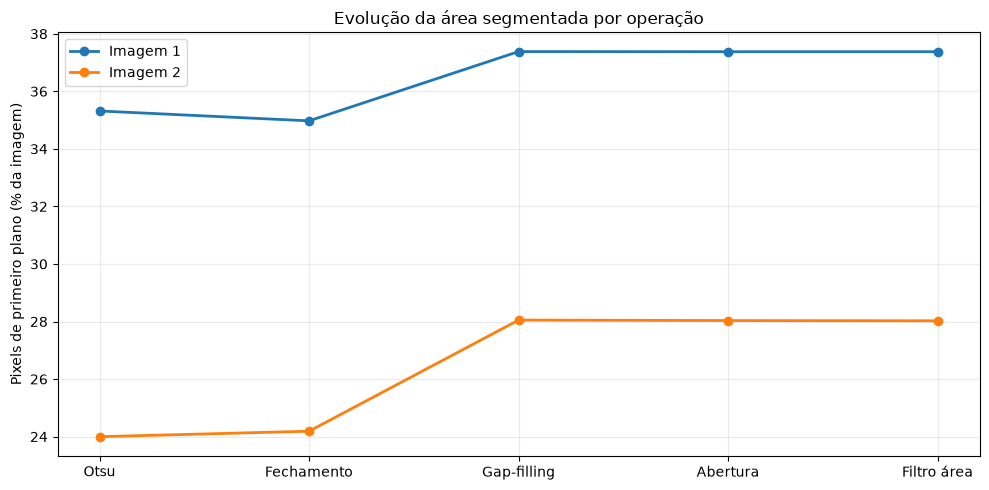


RESUMO DAS ALTERAÇÕES
Imagem 1: 16 → 16 componentes válidos; 17 → 16 componentes brutos; 6310 pixels preenchidos (2.41% da imagem).
Imagem 2: 58 → 57 componentes válidos; 211 → 60 componentes brutos; 74159 pixels preenchidos (3.86% da imagem).


In [27]:
# GRÁFICO 1 — componentes válidos antes versus depois, por imagem.
if RESULTADOS:
    posicoes = np.arange(len(RESULTADOS))
    antes = [r["contagem_antes"] for r in RESULTADOS]
    depois = [r["contagem_depois"] for r in RESULTADOS]
    largura = 0.34

    fig, ax = plt.subplots(figsize=(9, 4.8))
    barras_a = ax.bar(posicoes - largura / 2, antes, largura, label="Antes da morfologia")
    barras_d = ax.bar(posicoes + largura / 2, depois, largura, label="Depois da morfologia")
    ax.bar_label(barras_a, padding=3)
    ax.bar_label(barras_d, padding=3)
    ax.set_xticks(posicoes, [r["nome"] for r in RESULTADOS])
    ax.set_ylabel(f"Componentes válidos (área ≥ {RESULTADOS[0]['area_minima']} px)")
    ax.set_title("Contagem de componentes conectados antes e depois")
    ax.legend()
    ax.set_ylim(0, max(antes + depois) * 1.18)
    ax.grid(axis="y", alpha=0.25)
    plt.tight_layout()
    plt.show()

    # GRÁFICO 2 — componentes válidos e rejeitados, com a mesma escala por imagem.
    fig, eixos = plt.subplots(1, len(RESULTADOS), figsize=(12, 4.8), squeeze=False)
    for ax, r in zip(eixos.flat, RESULTADOS):
        validos = [r["contagem_antes"], r["contagem_depois"]]
        rejeitados = [r["bruto_antes"] - validos[0], r["bruto_depois"] - validos[1]]
        bases = np.arange(2)
        barras_v = ax.bar(bases, validos, label="Válidos")
        barras_r = ax.bar(bases, rejeitados, bottom=validos, label=f"Descartados (< {r['area_minima']} px)")
        for i in range(2):
            ax.text(i, validos[i] + rejeitados[i] + max(2, r["bruto_antes"] * 0.025),
                    str(validos[i] + rejeitados[i]), ha="center", fontsize=10)
        ax.set_xticks(bases, ["Antes", "Depois"])
        ax.set_ylim(0, max(r["bruto_antes"], r["bruto_depois"]) * 1.18 + 1)
        ax.set_title(r["nome"])
        ax.set_ylabel("Componentes detectados")
        ax.grid(axis="y", alpha=0.2)
    handles, labels = eixos[0, 0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="lower center", ncol=2, bbox_to_anchor=(0.5, 0.005))
    fig.suptitle("Efeito combinado da morfologia e do filtro de área", fontsize=13)
    plt.tight_layout(rect=(0, 0.09, 1, 0.94))
    plt.show()

    # GRÁFICO 3 — alteração da ocupação da máscara durante cada operação.
    etapas = ["Otsu", "Fechamento", "Gap-filling", "Abertura", "Filtro área"]
    fig, ax = plt.subplots(figsize=(10, 5))
    for r in RESULTADOS:
        ocupacao = [
            100.0 * r["binaria"].mean(),
            100.0 * r["fechada"].mean(),
            100.0 * r["preenchida"].mean(),
            100.0 * r["aberta"].mean(),
            100.0 * r["mascara_final"].mean(),
        ]
        ax.plot(etapas, ocupacao, marker="o", linewidth=2, label=r["nome"])
        print(f"{r['nome']}: ocupação por etapa (%) = " + ", ".join(f"{x:.2f}" for x in ocupacao))
    ax.set_ylabel("Pixels de primeiro plano (% da imagem)")
    ax.set_title("Evolução da área segmentada por operação")
    ax.legend()
    ax.grid(alpha=0.25)
    plt.tight_layout()
    plt.show()

    print("\nRESUMO DAS ALTERAÇÕES")
    for r in RESULTADOS:
        total = r["cinza"].size
        print(f"{r['nome']}: {r['contagem_antes']} → {r['contagem_depois']} componentes válidos; "
              f"{r['bruto_antes']} → {r['bruto_depois']} componentes brutos; "
              f"{int(r['buracos'].sum())} pixels preenchidos ({100 * r['buracos'].sum() / total:.2f}% da imagem).")
else:
    print("Adicione as duas imagens obrigatórias e execute novamente para exibir os gráficos.")

## Discussão dos resultados e limitações

**Imagem 1 — máscara artificial com anéis:** a contagem permaneceu em **16 componentes válidos antes e depois**, porque um anel com centro vazio já é considerado conectado. O gráfico da área segmentada evidencia o impacto do preenchimento dos buracos mesmo sem aumento ou redução da contagem. Portanto, uma máscara visualmente mais completa não precisa apresentar uma contagem diferente.

**Imagem 2 — esfregaço sanguíneo:** a limiarização invertida identifica regiões arroxeadas contra o fundo claro. Foram encontrados **58 componentes válidos inicialmente e 57 depois**, adotando o mesmo filtro de área mínima de 200 pixels. A quantidade de componentes brutos caiu de **211 para 60**, indicando redução de muitos fragmentos pequenos; entretanto, células encostadas ou sobrepostas podem permanecer unidas e provocar subcontagem.

**O que os gráficos medem:** (1) contagem de componentes conectados válidos; (2) quantidade de componentes brutos e pequenos componentes rejeitados por tamanho; (3) percentual da imagem ocupado pelos pixels segmentados ao longo das operações. A contagem usa **BFS com conectividade de 8 vizinhos** e o preenchimento usa **BFS do fundo com 4 vizinhos**, ambos implementados manualmente. O filtro de área é aplicado tanto antes quanto depois para tornar a comparação consistente.

**Limitação relevante:** as imagens não representam o mesmo tipo de objeto. A Imagem 1 é um teste morfológico sintético; a Imagem 2 contém hemácias e outros elementos, e **hemácias não possuem núcleo**. Por isso, os números representam **objetos/células candidatos segmentados**, não a quantidade validada de núcleos celulares. A redução de componentes e a alteração de área **não comprovam melhoria de acurácia**; seria necessária uma anotação manual de referência para avaliar erro de contagem.

**Reprodução e apresentação:** os painéis visuais, as tabelas e os três gráficos ficam exibidos no próprio notebook pré-executado; não há exportação automática de arquivos. Para testar outras imagens, substitua os arquivos em `data/` e ajuste `NOMES_ARQUIVOS` e `CONFIG` na etapa de pré-processamento.